# **추천시스템**

## **Part 1. 추천 시스템 기초**

### **1. 추천 시스템이란?**
- 사용자의 행동 기록과 아이템 정보를 바탕으로, 사용자가 좋아할 만한 아이템을 예측해 골라 주는 시스템

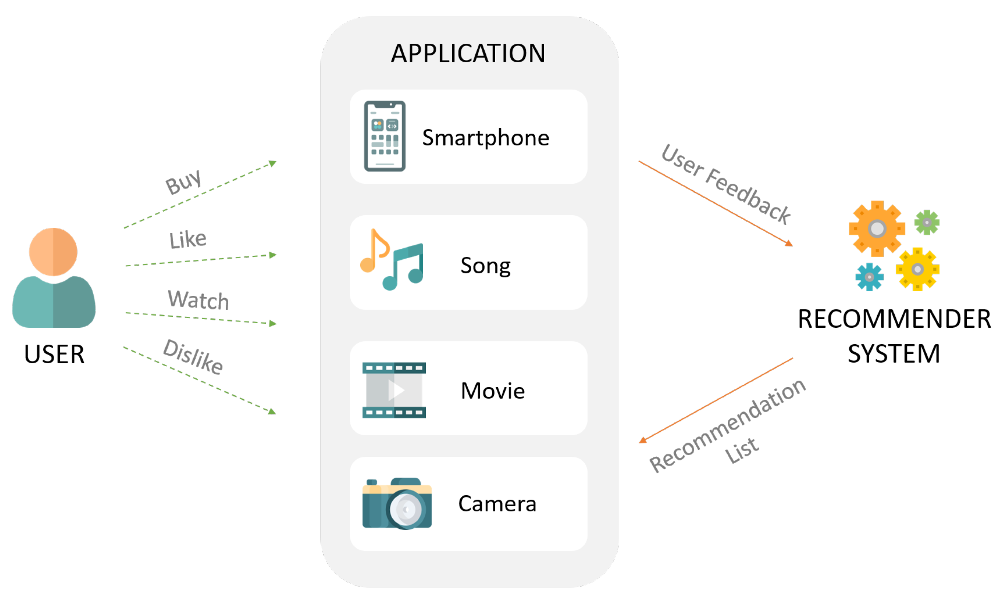

- 추천 시스템이 필요한 이유
    - **고객 입장**
        - 찾는 시간, 노력이 줄어듦
        - 몰랐던 취향의 아이템 발견 가능
            
            -> **검색**은 사용자가 이미 알고 있는 것을 찾게 돕고, **추천**은 아직 모르는 것을 발견하게 도움

    - **기업 입장**         
        - 이용 시간, 구매 전환, 재방문 늘릴 수 있음
        - 비인기 아이템(롱테일) 노출 가능

#### **1-1. 사용 데이터 종류와 특징**

**1. 명시적 데이터 (Explicit Data)**

의미 : 고객들에 의해 입력된 데이터. 사용자가 선호를 직접 표현한 데이터.

예시 : 별점, 좋아요·싫어요, 리뷰

- 장점 : 비교적 분명한 선호와 불호 존재 -> 사용자 취향 정확히 반영
- 단점
    - 평가를 남기는 사람이 적고, 남기더라도 본 것 중 일부에만 남김 -> 명백한 데이터 얻기 어려움
    - 사람 취향은 변함 -> 과거와 현재의 선호도가 동일한지 알 수 없음
    - 사람마다 점수를 주는 기준이 다름


**2. 암시적 데이터 (Implicit Data)**

의미 : 고객들의 행동을 기반으로 수집된 데이터. 행동에서 선호를 간접적으로 추측하는 데이터

예시 : 조회수, 클릭, 구매, 시청 시간, 검색

- 장점 : 사용자가 따로 입력하지 않아도 대량으로 쌓여 얻기 쉬움
- 단점 
    - 행동이 곧 선호라고 단정 불가
        - 행동이 있어도 잘못 클릭했거나 선물로 구매할 가능성 존재 -> 좋아한다는 보장 없음
        - 행동이 없어도 아이템을 아직 못 봤을 수 있음 -> 싫어한다는 보장 없음

-> 실제 서비스에서는 암시적 데이터가 훨씬 많아, 두 가지 섞는 경우가 대부분!

#### **1-2. 추천시스템의 분류**

**무엇을 근거로 추천하느냐**에 따라 나뉨
- 내용(콘텐츠) 기반 필터링 -> 아이템 유사도를 근거로
- 협업 필터링 -> 다수 사용자의 행동 패턴을 근거로
- 하이브리드 -> 두 시스템의 조합

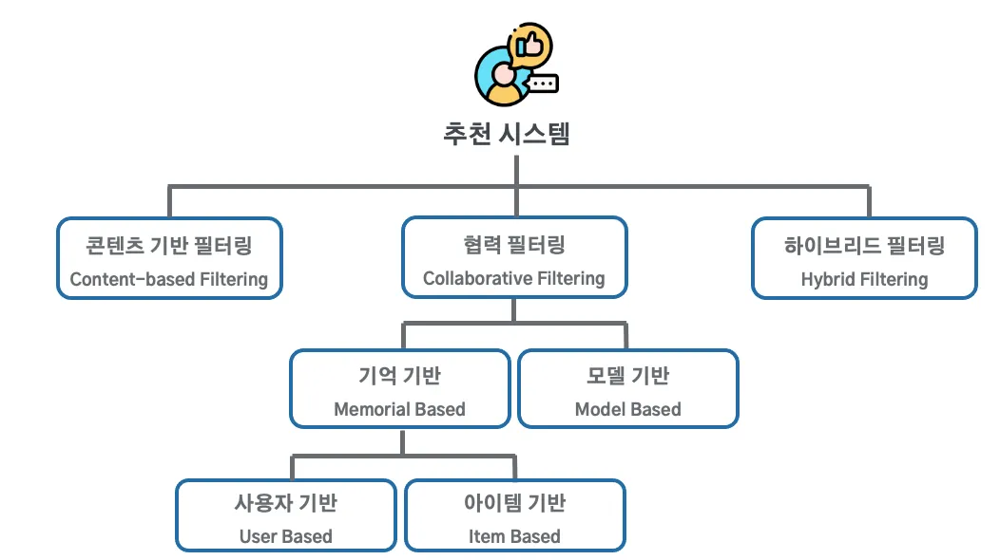

**1. 내용 기반 필터링 (Content-Based Filtering)**
- **콘텐츠 유사도 기반**으로 사용자에게 추천하는 방법
- 사용자가 이용하거나 선택한 아이템과 **특징이 비슷한 아이템** 추천

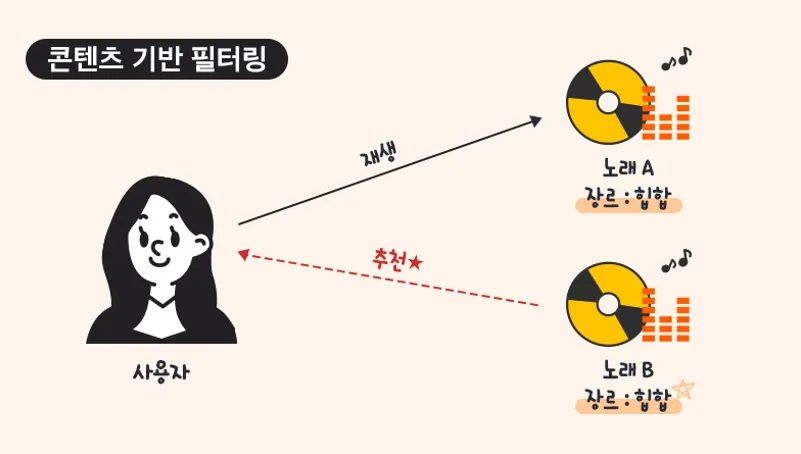

**2. 협업 필터링 (Collaborative Filtering)**
- 서비스 내 **다수의 사용자로부터 얻은 선호도 정보**를 기반으로 추천
- 두 사용자 취향이 비슷할 경우, **한 사람이 좋아한 아이템을 다른 사람도 좋아할 가능성이 높다**고 보는 방식!

1. **사용자 기반(User-Based Filtering)** : 특정 사용자와 **유사한 취향의 사용자**가 선호한 아이템 추천
2. **아이템 기반(Item-Based Filtering)** : 사용자가 선호한 아이템과 유사한 아이템 추천

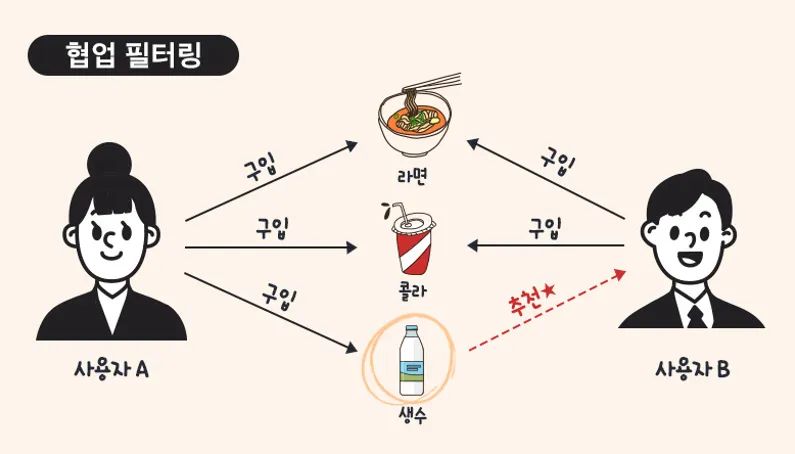

**3. 하이브리드 필터링 (Hybrid Filtering)**
-  2가지 이상 다양한 종류의 **추천 시스템 알고리즘 조합**하여 만들어진 방식
- **콘텐츠 기반 필터링과 필터링 각각의 단점들 보완** 위해 제시

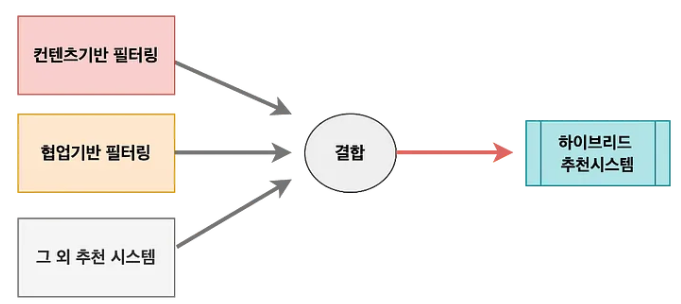

## **내용 기반 필터링 (Content-Based Filtering)**

### **2-1. 사용자 프로필**

: 사용자가 어떤 특성을 좋아하는지 정리한 정보

**추천 시스템에 사용되는 데이터**
- **직접 지정형** : 사용자가 자신의 취향을 직접 알려주는 방식
- **간접 지정형** : 사용자의 과거 행동 이력에서 취향을 추론하는 방식

**사용자 프로필 획득 방식**

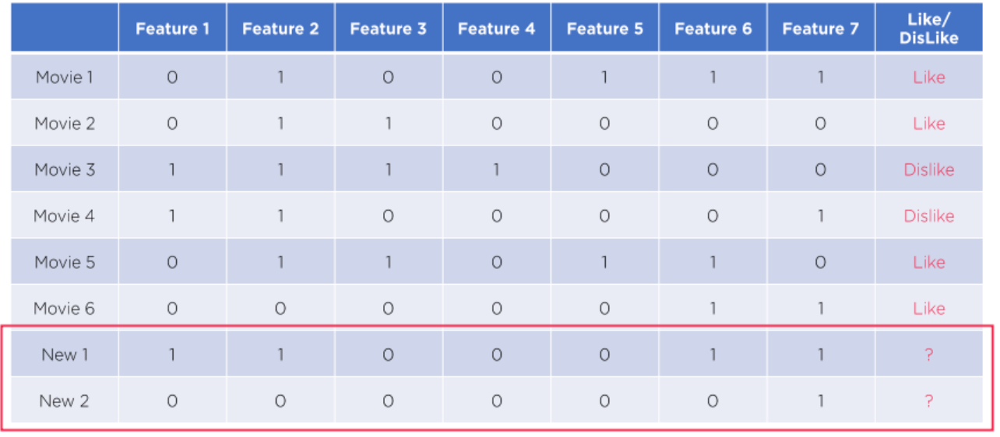

1. **사용자가 가지고 있는 아이템 특성 가중치의 평균 값 활용**
    - 특성 가중치 : 아이템이 각 특성을 얼마나 가지고 있는지 나타낸 값(0~1)

2. **설문, 키워드 입력, 평가 같은 방법으로 사용자의 기호를 따로 파악**
    - 명시적 피드백
        - 좋아요/싫어요, 0~5점 평점
        - 사용자가 쓴 댓글 (긍정/부정 별도 분석 필요)

    - 암시적 피드백
        - 검색 로그, 구매, 저장, 북마크, 방문한 페이지
        - 사용자가 따로 평가하지 않아도 수집 가능

3. **유저의 평가를 바탕으로 분류(Classification) 문제로 해결**
    - 아이템에 대한 유저의 기존 평가 $\{r_1,r_2, …r_n\}$ 를 정답 라벨로 사용
    
    -> 새 아이템에 유저가 어떤 평가를 줄지(좋아요/싫어요, 또는 1~5점 중 몇 점) 예측하는 **분류 문제**
    
아이템의 특징이 입력, 유저의 평가가 정답인 구조라서 결정 트리, 랜덤 포레스트, KNN 같은 분류 모델 적용 가능!

### **2-2. 유사도 (Similarity)**

: 두 대상이 얼마나 비슷한지 나타내는 숫자

- 아이템 정보(텍스트, 이미지, 영상 등)를 **숫자 벡터로 변환**한 뒤 유사도를 계산
- 사용자와 아이템을 **같은 기준(feature)**으로 표현해야 서로 비교 가능
- 사용자가 선호하는 아이템과 비교해 **유사도가 높은 아이템을 선별**해 추천
- STEP
    
    **1) 아이템을 숫자로 변환**
    
    - **아이템 정보 활용**
        - 예: 영화의 장르, 제작 국가, 감독, 출연 배우, 등급 등
        - 이런 속성을 데이터 사이언스 용어로 **feature**라 부름
    - **테이블 형태로 데이터 정리**
        - 행: 영화 제목 (예: '라라 랜드')
        - 열: 아이템의 feature
        - 셀: feature 값
    - **숫자로 변환하기 (원-핫 인코딩)**
        - 텍스트 데이터를 숫자 벡터로 변환해 컴퓨터가 이해할 수 있도록
        - 예: 장르 (뮤지컬, 액션, 코미디) → 각각의 장르를 독립적인 feature로 변환
        - 속하면 1, 아니면 0 부여
        - 결과: [1, 0, 0, 1, ...]
    
    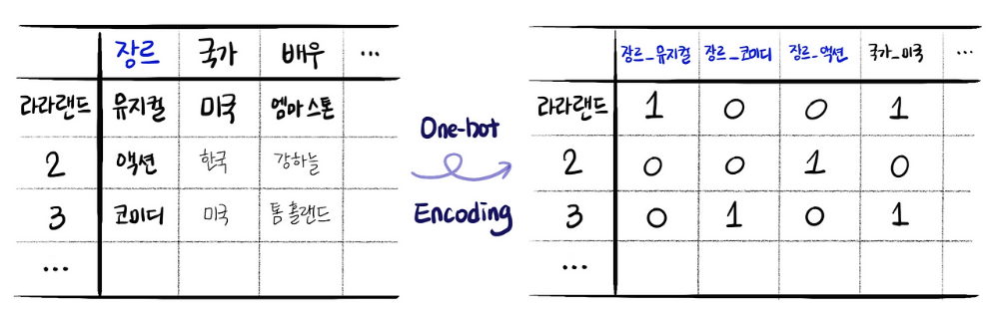
    
    
    **2) 사용자를 숫자로 변환**
    
    - **사용자의 취향 파악**
        - 직접 입력한 프로필 정보
        - 시청 기록을 통한 간접적 정보
    - 사용자도 아이템과 **동일한 n개의 feature**로 표현 → 벡터 계산 가능
    
    
    **3) 유사도 계산**
    
    - **벡터란?**
        - n개의 feature로 만들어진 데이터 → n차원의 벡터로 표현 가능
    - **벡터 내적 (dot product)**
        - 두 벡터의 동일 위치 값들끼리 곱한 후 모두 더한 값
        - **유사성(similarity)**: 내적 값이 클수록 두 벡터의 유사성이 높음
        - 0과 1로만 된 벡터라면 내적은 **겹치는 feature의 개수**와 같음
    
    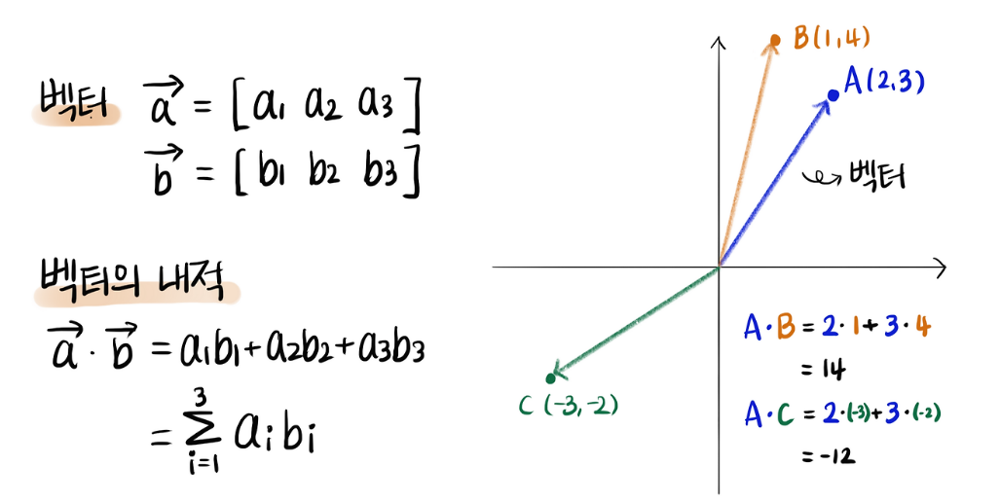
    
    **영화 추천 사례**
    
    - 벡터 A는 사용자, 벡터 B/C는 서로 스타일이 굉장히 다른 두 영화이다. 위의 계산처럼 벡터 A - 벡터 B의 내적이 더 큰 경우, 사용자 A는 B 영화와 더 유사한 성향을 보인다고 할 수 있다. 따라서 C 영화보다는 B 영화를 추천해주는 것이 사용자 A의 선택을 받을 가능성이 더 높다.

- cf) 유사도 방식의 종류
    
    
    | No. | **기반** | **명칭** | **설명** |
    | --- | --- | --- | --- |
    | 1 | 집합 | 자카드 유사도 | 아이템 집합 간의 <u>**교집합 크기**</u>를 이용하여 측정 |
    | 2 | 각도 | 코사인 유사도 | 아이템의 <u>**벡터 사이의 각도**</u>를 이용하여 측정 |
    | 3 | 거리 | 유클리디안 거리 | 아이템의 <u>**벡터 사이의 거리**</u>를 이용하여 측정 |
    | 4 | 상관관계 | 피어슨 상관계수 | 아이템의 <u>**벡터간 선형 상관 관계**</u>를 이용하여 측정 |
    
    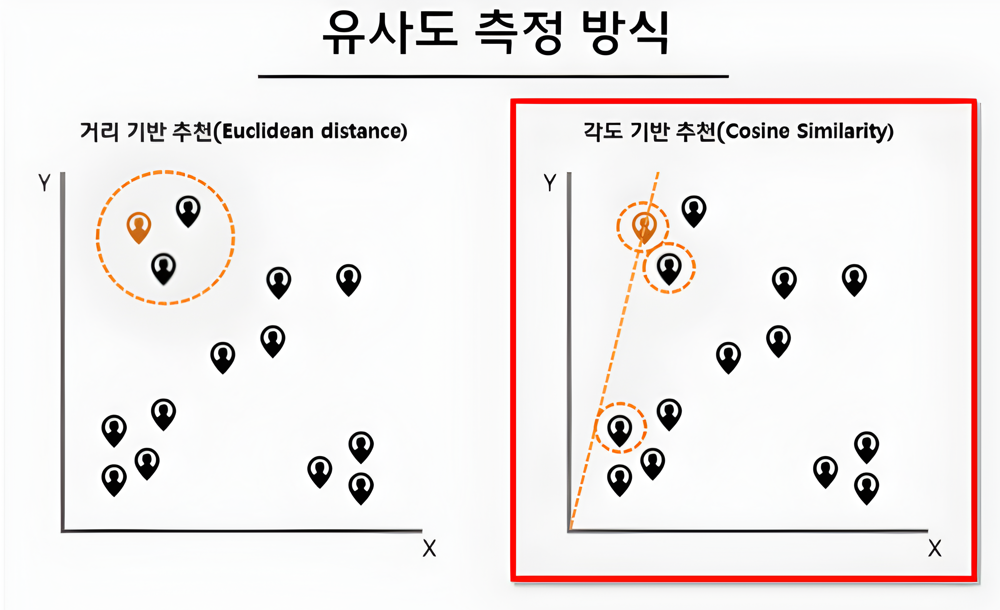

    - **코사인 유사도(Cosine Similarity)** 
    : 두 벡터 사이의 각도를 측정한 지표로, 각도가 작을수록 값이 1에 가까워짐. **값이 클수록 비슷함.**
        
    - **유클리드 거리(Euclidean Distance)**: 두 점 사이의 거리를 측정한 지표로, 값이 작으면 두 데이터가 가까이 있어 유사하다는 의미.


### **2-3. TF-IDF (Term Frequency - Inverse Document Frequency)**

: **특정 문서ㅔ는 자주 나오고 다른 문서에는 드문 단어**에 높은 값을 주는 방법

- **TF (Term Frequency)** : **단어 빈도**로, 특정 문서에 자주 나올수록 커짐
- **IDF (Inverse Document Frequency)** : **역문서 빈도**로, 그 단어가 등장한 문서 수가 많을수록 작아짐

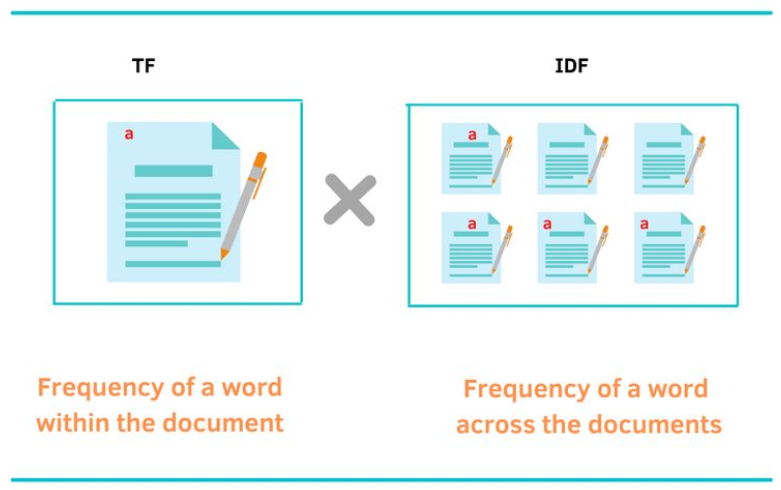

- **계산식**
    - $TF(d,t)$ : 특정 문서 d에서의 특정 단어 t의 등장 횟수
    - $DF(t)$ : 특정 단어 $t$가 등장한 문서의 수
    - $n$ : 전체 문서의 수

    - $IDF(d,t)$ :

    $$
    idf(d,t) = log(\frac{n}{1+df(t)})
    $$

    - TF-IDF 계산 예시
        
        $$
        TF-IDF = TF(d,t) \times IDF(d,t)
        $$
        
    -> TF-IDF가 높을수록 그 단어가 다른 문서들보다 **해당 문서에서 더 중요한 역할**을 한다는 뜻

- **예시**
    1. 영화마다 줄거리를 **TF-IDF 벡터**로 변환
    2. 사용자가 재밌게 본 영화의 벡터와 다른 영화들의 벡터를 **코사인 유사도**로 비교
    3. **유사도가 높은 영화를 추천**

    예를 들어 "우주", "탐사" 단어들의 TF-IDF가 높은 영화를 좋아한 사용자에게는, 이 단어들이 비슷하게 중요하게 나타나는 다른 SF 영화가 추천됨!


### **2-4. 내용 기반 필터링의 장단점**

- **장점**
    - 아이템 **콜드 스타트 문제 해결** -> 속성만 있으면 신규 아이템도 추천 가능
    - 내 기록만으로 프로필을 만들기 때문에 **다른 사용자의 데이터가 필요 없음**
    - 어떤 feature 때문에 추천했는지 보여 줄 수 있어 **추천 이유를 설명하기 용이**
- **단점**
    - feature로 담을 수 있는 정보에 한계가 있음 -> 속성 정보가 부족하거나 품질이 낮으면 **정확도가 떨어짐**
    - **비슷한 것만 계속 추천** (과도한 특화, Over-specialization) -> 새로운 장르 발견 어려움
    - **기록이 없는 신규 사용자**는 추천하기 어려움 (사용자 콜드 스타트)

**Cold start problem** : 충분한 정보가 수집되지 않아 적절한 제품을 추천해주지 못하는 문제
 
- **아이템 콜드 스타트**: 새 아이템에 평가가 없음 → 내용 기반으로 **해결 가능**
- **사용자 콜드 스타트**: 새 사용자의 기록이 없음 → 내용 기반으로도 **해결 어려움**


## **3. 협업 필터링 (Collaborative Filtering)**

### **3-1. 메모리 기반 협업 필터링 (Memory-Based Collaborative Filtering)**

- 시스템에 저장된 사용자 - 아이템 평점을 **그대로 꺼내서** 새 아이템의 평점을 예측하는 방법
- 별도의 학습 단계 없이 비슷한 사용자나 아이템, 즉 **"이웃"** 을 찾아 쓰기 때문에 **이웃 기반 협업 필터링(Neighborhood-based CF)** 이라고도 부름
- 협업 필터링 중 비교적 초기에 개발된 방식

#### **2가지 형태의 접근법**

**1. 사용자 기반(User-based) 접근** : 나와 취향이 비슷한 사용자(이웃)의 평점을 활용해 내 평점을 예측하고 추천

- 나와 유사도가 가장 높은 사용자 `TOP-N`명을 이웃으로 선정
- 이웃들의 평점을 **유사도로 가중평균**해 내가 아직 평가하지 않은 아이템의 평점을 예측 (유사도가 높은 이웃일수록 큰 영향)
- 예측 평점이 높은 아이템을 추천

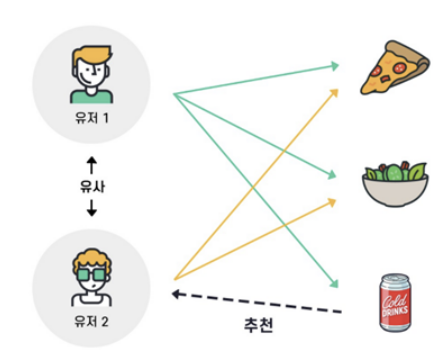
- 추천하고자 하는 target user와 **유사한 사용자들의 평점**을 활용

- **사용자 간 유사도 계산**

    평점 데이터에서는 유사도를 구할 때 피어슨 상관계수를 주로 사용

    $$
    sim(u, v) = \frac{\sum_{i} (r_{ui} - \bar{r}_u)(r_{vi} - \bar{r}_v)}{\sqrt{\sum_{i} (r_{ui} - \bar{r}_u)^2} \sqrt{\sum_{i} (r_{vi} - \bar{r}_v)^2}}
    $$

    - $r_{ui}$: 사용자 $u$가 아이템 $i$에 준 평점
    - $\bar{r}_u$ : 사용자 $u$의 평균 평점
    - $i$ : 두 사용자가 **모두 평가한** 아이템

    **예측 평점**
    유사도를 구했다면, 이웃들의 평점을 합쳐서 예측합니다.

    $$
    \hat{r}_{ui} = \bar{r}_u + \frac{\sum_{v} sim(u, v)\,(r_{vi} - \bar{r}_v)}{\sum_{v} |sim(u, v)|}
    $$

    이웃들이 그 아이템을 자기 평균보다 얼마나 높게(낮게) 줬는지를 유사도만큼 반영해서, 내 평균에 더하는 방식입니다.

**2. 아이템 기반(Item-based) 접근** : 내가 평가한 아이템들과 **평점 패턴이 비슷한 아이템**을 찾아 추천하는 방식

- 아이템의 속성이 아닌 **사용자들이 그 아이템을 함께 좋아하고 싫어한 패턴**으로 유사도 판단
- 사용자는 계속 늘어나고 취향도 바뀌지만 아이템끼리의 관계는 상대적으로 덜 변함 -> 아이템 유사도를 **미리 계산해 두고 재사용**하기 좋음

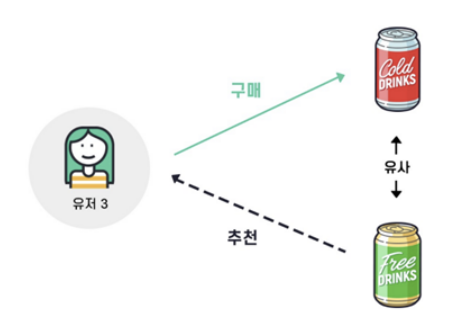
- 추천하고자 하는 target item과 **유사한 아이템**의 평점을 활용

**User-based VS Item-based**

| 기준 | **사용자 기반 (User-based)** | **아이템 기반 (Item-based)** |
| --- | --- | --- |
| **정확성** | **아이템 수**가 사용자 수보다 많을 때 유리 | **사용자 수**가 아이템 수보다 많을 때 유리 |
| **공간, 효율성** | **사용자 간 유사도**를 저장 → 사용자가 많으면 부담 | **아이템 간 유사도**를 저장 → 아이템이 많으면 부담 |
| **안정성** | 사용자 변화의 영향을 많이 받음 → 아이템이 **자주 바뀌고** 사용자 **유입이 적은** 환경에 적합 | 아이템 목록이 잘 **변하지 않는** 환경에서 안정적 |
| **계산 속도** | 추천할 때마다 비슷한 사용자를 새로 찾아야 함 | 아이템 유사도를 미리 계산해 두고 재사용 → **빠름** |
| **다양성** | 비슷한 사용자가 평가한 독특한 아이템까지 추천 → **의외성, 참신성**이 강점 | 기존에 본 아이템과 비슷한 추천이 많아 다양성은 상대적으로 부족 |
| **활용 예** | 뉴스, 소셜 미디어(알 수도 있는 친구 추천), 음악 추천 서비스 | 아마존 등 사용자가 많은 대형 플랫폼 |

### **3-2. 메모리 기반 협업 필터링의 한계**

#### **1. 희소 행렬 문제**

: 주어진 평점, 선호도 데이터가 적을 경우 성능이 저하되는 문제

- 실제 사용자 - 아이템 행렬은 대부분의 칸이 비어 있음 (sparse matrix, 희소 행렬)

**데이터가 희소하면 생기는 문제**
- 두 사용자가 함께 평가한 아이템이 적어 **유사도를 믿기 어려움**
    - 공통 아이템이 1개뿐이어도 코사인 유사도가 1로 나올 수 있음
- 비슷한 이웃을 찾지 못하면 **예측 자체가 어려움**

-> **모델 기반 협업 필터링(Model-based CF) 이용** : 이웃을 직접 비교하는 대신, 관측된 평점으로 사용자와 아이템의 특징을 학습해 빈칸 채우는 방법!

#### **2. 콜드 스타트 문제**

: 데이터가 충분히 쌓이지 않아 적절한 추천 하지 못하는 문제

- 협업 필터링은 행동 기록에만 의존하기 때문에, 기록이 없는 대상에게는 추천 불가능
- 크게 **2가지 상황**에서 발생:
    - **신규 사용자** : 평가 기록이 없어 비슷한 이웃을 찾을 수 없음
        - 예시 :  넷플릭스에 방금 가입한 사용자
    - **신규 아이템** : 아무도 평가하지 않아 추천 후보에 오르지 못함
        - 누군가 처음 평가하기 전까지는 추천되지 않는다는 의미에서 **first-rater 문제**라고도 불림
        - 예시 : 오늘 새로 등록된 영화

**-> 해결 방법**

- 가입할 때 좋아하는 장르나 작품을 **직접 지정하도록** 하기 (넷플릭스, 왓챠 가입 화면)
- 새 아이템에는 **내용 기반 필터링**을 함께 쓰는 하이브리드 방식
- 임베딩을 쓰는 모델이라면, 같은 카테고리 아이템들의 **임베딩 평균**으로 새 아이템을 임시로 표현하기
- **인구통계학적 정보** (나이, 성별 등) 활용해 비슷한 사용자 그룹 추정

#### **3. 확장성 문제**

: 아이템과 사용자가 계속 늘어날수록 계산량이 커지는 문제 (Scalability)

아이템 하나의 평점 예측을 위해서는 그 아이템을  평가한 사용자들과의 유사도를 전부 구해야 함. 사용자와 아이템이 늘어날수록 계산량도 계속 커짐. 데이터를 샘플링하거나 줄이면 빨라지긴 하나, 그만큼 추천 품질도 떨어짐.

-> **KNN 협업 필터링 이용** : 모든 사용자가 아닌, 유사도가 높은 k명의 이웃만 골라 예측하는 방법
- 이웃은 예측하려는 아이템을 **실제로 평가한 사용자** 중에서만 선택 가능
- k가 너무 작으면 소수의 의견에 예측이 많이 흔들리고, 너무 크면 덜 비슷한 사용자까지 섞여 예측이 흐려짐

### **3-3. 모델 기반 협업 필터링 (Model-Based Collaborative Filtering)**

: 관측된 평점 데이터로 **예측 모델을 학습**하고, 데이터의 패턴을 모델의 파라미터에 담아 관측되지 않은 평점을 예측하는 방법

- **메모리 기반**: 추천이 필요할 때마다 저장된 평점을 직접 비교해 이웃을 찾음
- **모델 기반**: 평점 데이터를 먼저 **압축된 모델로 요약**해 두고, 추천은 이 모델만으로 수행

**동작 단계**

1. **학습 단계 (Training)** : 이미 존재하는 평점을 가장 잘 설명하는 모델의 파라미터를 찾음 -> 추천과 별도로 미리 수행하며, 새 데이터가 쌓이면 주기적으로 다시 학습
2. **예측 단계 (Inference)** : 학습된 파라미터로 비어 있는 칸의 평점을 계산 -> 추천이 필요한 시점에 빠르게 수행

**메모리 기반 vs 모델 기반**

| 구분 | 메모리 기반 | 모델 기반 |
| --- | --- | --- |
| 학습 단계 | 없음 | 있음 |
| 예측에 쓰는 것 | 원본 평점 데이터 | 학습된 모델 |
| 희소한 데이터 | 함께 평가한 아이템이 적어 유사도 근거가 부족 | 전체 패턴을 학습해 빈칸을 일반화 |

#### **잠재 요인 (Latent Factor)**

: 평점에 직접 드러나지는 않지만, 사용자와 아이템 사이의 관계를 결정짓는 **숨은 특성**

- 모델이 **관측된 데이터를 바탕으로 수치적으로 추정**하는 값
- “취향”, ”성향” 과 같이 **실제 데이터에는 없는 개념을 숫자로 표현**

#### **Latent Factor Model**

: 사용자와 아이템을 같은 잠재 공간 위 벡터로 나타내고, 두 벡터의 관계로 평점을 설명하는 모델

- 평점 행렬을 `사용자-잠재 요인` 행렬과 `아이템-잠재 요인` 행렬로 나누어 학습

| 구분 | Factor Model | Latent Factor Model |
| --- | --- | --- |
| 축의 개수 | 사람이 정함 | 사람이 정함 (하이퍼파라미터 k) |
| 축의 의미 | 사람이 미리 정함 (예: 액션, 로맨스) | **학습 과정에서 정해짐** → 사람이 해석하기 어려움 |

**Factor model vs Latent Factor model**
- **Factor model** : 축(차원)이 무엇을 뜻하는지 사람이 미리 정해 둔 공간
    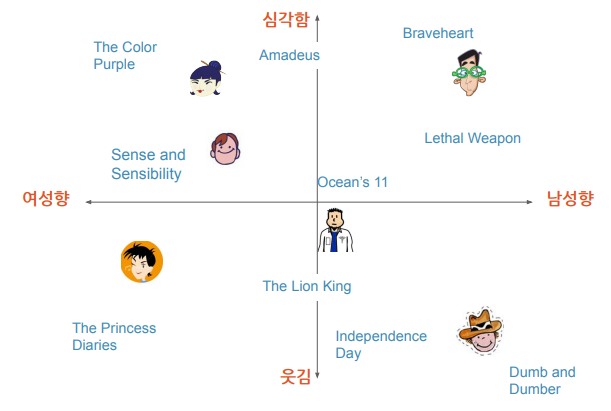

- **Latent Factor model** : 축의 개수만 정해 두고, 각 축이 무엇을 뜻하는지는 학습으로 정해지는 공간
    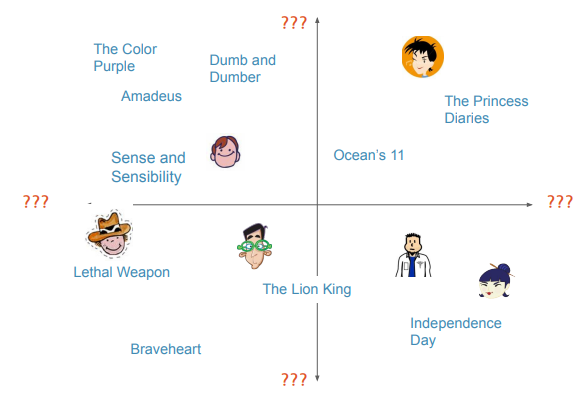


#### **행렬 분해**

: 큰 평점 행렬을 **작은 행렬 두 개의 곱**으로 쪼개는 방법

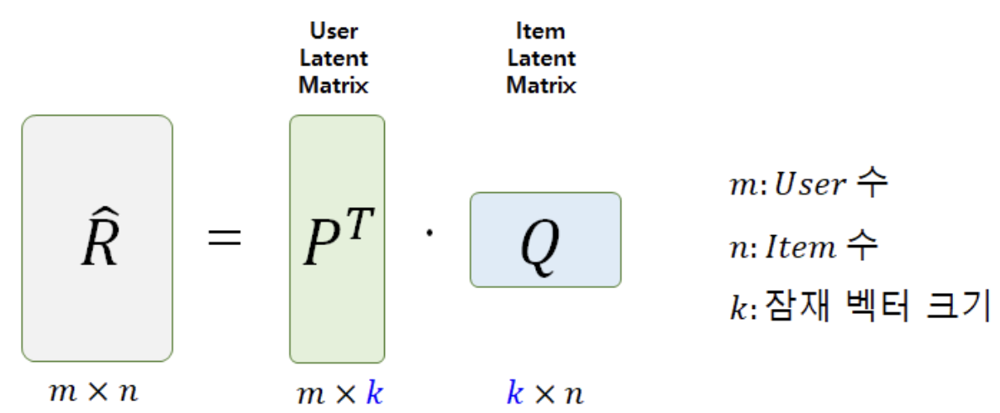

$$
\hat{R} = P^T Q
$$

- **$\hat{R} (m \times n)$**: 예측 평점 행렬
- **$P (k \times m)$**: 사용자 잠재 요인 행렬, 각 열이 사용자 벡터 $p_u$
- **$Q (k \times n)$** : 아이템 잠재 요인 행렬, 각 열이 아이템 벡터 $q_i$
- $k$ : 잠재 요인의 개수 (하이퍼파라미터)

예측 평점은 두 벡터의 **내적으로 계산!**

$$
\hat{r}_{ui} = p_u^T q_i = \sum_{s=1}^{k} p_{su}\, q_{si}
$$

-> 사용자 u의 아이템 i에 대한 예측 평점

#### **메모리 기반과의 차이**

|  | 메모리 기반 | 모델 기반 |
| --- | --- | --- |
| **예측 방식** | 비슷한 사용자와 아이템을 직접 찾음 | 학습한 벡터를 내적 |
| **확장성** | 추천할 때마다 많은 유사도 계산이 필요 | 학습은 미리 하고, 추천 시엔 벡터 내적만 계산 → 빠름 |
| **콜드 스타트** | 해결 어려움 | 해결 어려움 (상호작용이 없으면 벡터를 학습할 수 없음) |
| **장점** | 추천 이유를 설명하기 쉬움 | 데이터를 압축해 예측이 빠르고 일반화에 유리함 |

-> 행렬 분해는 희소성과 확장성 문제를 많이 해결했지만, 결국 **내적이라는 선형 계산**으로 예측한다는 한계가 남음.

# **딥러닝 기반 추천 시스템**

## **1. VAE 기반 협업 필터링 (Variational Autoencoder CF)**

: 사용자의 상호작용 기록을 신경망으로 **확률분포**로 압축한 뒤, 다시 복원하면서 아직 보지 않은 아이템의 선호를 예측하는 모델

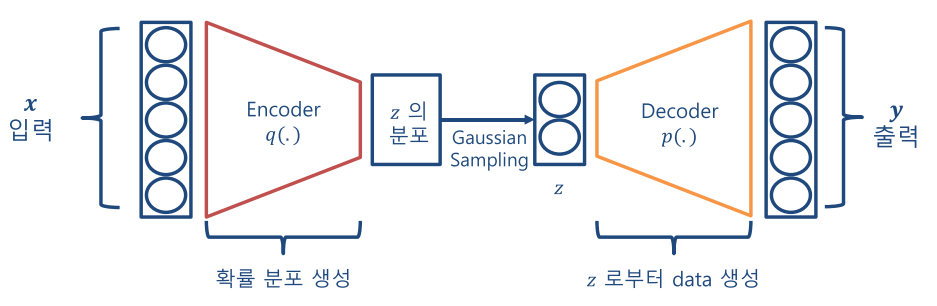

- 구조
    - 인코더
        - 사용자의 상호작용 벡터 $x_u$를 입력받아, 잠재 공간에서 평균 μ와 표준편차 σ로 변환
        - 즉 사용자의 취향을 하나의 고정된 좌표가 아니라 **분포 $q(z \mid x_u)$**로 추정
    - 샘플링
        - 인코더가 추정한 분포(μ, σ)에서 잠재 벡터 z를 무작위로 뽑아 디코더에 전달
    - 디코더
        - 잠재 벡터 z를 전체 아이템의 점수로 변환하고, **아이템별 선호 확률**을 출력
        - 이 확률이 높은 순서로 사용자가 아직 상호작용하지 않은 아이템을 추천

- 장점
    - 불확실성 반영: 사용자 표현을 점 추정이 아닌 확률 분포로 모델링해, 취향의 불확실성까지 함께 표현합니다.
    - 희소한 상호작용 데이터에서 강건: 기록이 적은 사용자도 과적합을 줄이고 비교적 안정적으로 표현할 수 있습니다.

- 대표 모델: Mult-VAE

### **1-1. MF의 한계와 딥러닝의 등장**

#### **MF의 한계**

**1. 선형성**

행렬 분해의 예측은 **내적**, 즉 요인별로 곱해서 더하기만 하는 구조. 그래서 각 요인이 점수에 따로따로 더해지고, 요인끼리 얽히는 효과는 표현하기 어렵다.

**2. 불확실성 무시**

일반적인 MF는 사용자마다 벡터를 딱 하나 학습함. 이를 **점 추정(Point Estimate)**이라고 함.

-> 기록이 5개뿐인 사용자와 5,000개인 사용자의 벡터를 **똑같이 확신**하고 사용하기 때문에, 기록이 적은 사용자의 추정이 불안정해도 이를 구분하지 못함.

**딥러닝 해법**

| MF의 한계 | 내용 | 딥러닝의 해법 |
| --- | --- | --- |
| **선형성** | 예측이 내적 하나로 결정되어 복잡한 조합 패턴을 표현하기 어려움 | **비선형 활성화 함수를 가진 신경망 사용** |
| **불확실성 무시** | 기록이 적은 사용자와 많은 사용자를 구분 없이 같은 확신도의 벡터 하나로 표현 | **평균과 분산을 함께 출력** |

#### **1-2. 왜 AutoEncoder(AE)가 아닌 VAE(Variational AE)인가?**

**AE** 

: 입력을 작은 벡터로 압축했다가 복원하는 신경망 모델

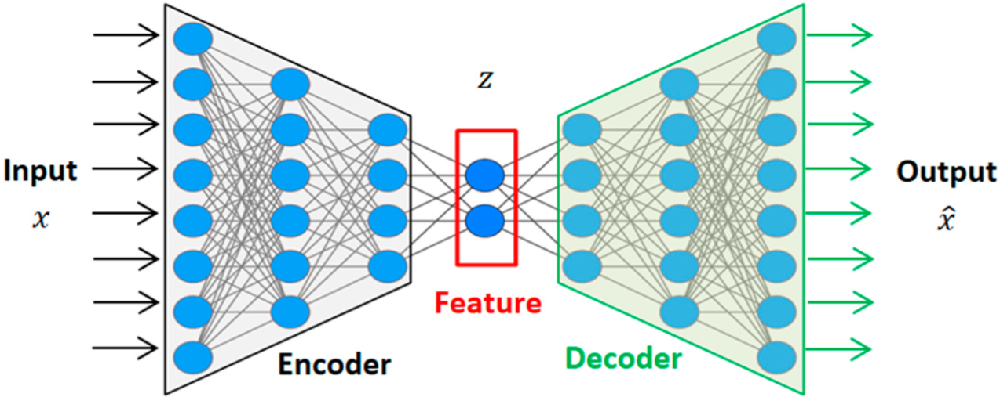

**VAE**

: 가운데 잠재 벡터를 점 하나가 아닌 **분포**로 표현하는 오토인코더

- **평균 μ**: 사용자 취향의 중심 위치
- **표준편차 σ**: 그 위치를 얼마나 확신할 수 없는지(불확실성)

**VAE가 더 안정적인 이유**

1. **점 하나가 아니라 그 주변을 사용해 학습**
학습할 때마다 μ 근처에서 z를 무작위로 뽑아 디코더에 넣음. 그래서 디코더는 μ에서 조금 벗어난 위치에서도 비슷한 추천이 나오도록 학습.

2. **기준 분포 쪽으로 당겨짐**
KL 항이 분포를 표준 정규분포 쪽으로 당기기 때문에, 기록 몇 개만으로 극단적인 위치로 가기 어려움.

**AE vs VAE**

| 구분 | AE | VAE |
| --- | --- | --- |
| **잠재 벡터 표현** | 단일 값 (Point Estimate) | 평균 μ와 표준편차 σ를 가진 정규분포 |
| **불확실성 반영** | 반영하지 않음 | 사용자별 σ로 표현 |
| **장점** | 구조가 단순함 | 기록이 적은 사용자에게도 안정적이고 일반화에 유리 |

### **1-3. VAE 기반 CF (Multi-VAE)의 작동 구조**

: 사용자의 상호작용 기록(0/1 벡터)을 입력받아, 인코더로 취향을 분포(μ, σ)로 요약하고 디코더로 전체 아이템의 선호 확률을 복원해 추천하는 구조

| 구성 요소 | 세부 내용 |
| --- | --- |
| **입력** ($x$) | 아이템 수만큼 긴 0/1 벡터로, 평점 데이터는 4점 이상만 1로 바꿔 사용 |
| **인코더** | 평균 μ와 표준편차 σ를 출력 |
| **잠재 벡터** ($z$) | μ, σ로 정해진 정규분포에서 샘플링한 벡터 |
| **디코더** | 모든 아이템의 점수를 계산한 뒤 softmax로 확률로 변환 |

### **1-4. VAE의 비밀 병기 : 목적 함수와 KL Divergence**

VAE는 ELBO라는 목적 함수를 최대화하며, 이 안에서 **정확한 복원**과 **잠재 공간 정규화**라는 두 가지 목표를 동시에 최적화함.

#### **목적 함수 ELBO (Evidence Lower Bound)**

: 데이터가 나올 로그 확률 하한을 키우는 방식

$\mathcal{L}(x; \theta, \phi) = \underbrace{E_{q_\phi(z|x)} [ \log p_\theta(x|z) ]}_{\text{재구성 오차 최소화 (Reconstruction Loss)}} - \underbrace{D_{\text{KL}}(q_\phi(z|x) || p(z))}_{\text{잠재 공간 정규화 (KL Divergence)}}$

**1.  복원 항 (첫 번째 항)**

- 디코더가 잠재 벡터 $z$를 사용하여 원래 입력 $x$를 최대한 비슷하게 복원하도록 만듬. (AE의 역할과 동일)

**2.  KL Divergence 항 (두 번째 항)**

- 인코더가 출력하는 잠재 분포 $q(z|x)$가 표준 정규분포 $p(z)$ 에서 크게 벗어나지 않도록 강제
- 이를 통해 일부 사용자 데이터에 대한 과적합을 막고, 잠재 공간이 불규칙해지지 않도록 **연속적이고** **부드럽게(Smooth)** 유지

#### **KL Divergence란?**

: 두 확률분포가 얼마나 다른지를 나타내는 값

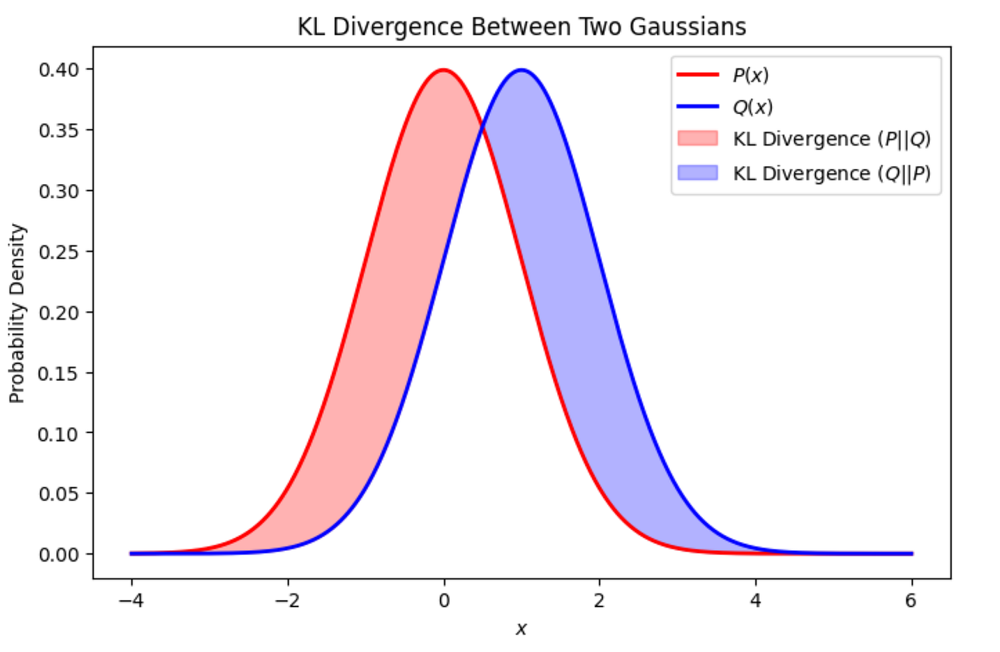

$$
D_{KL}\big(\mathcal{N}(\mu, \sigma^2) \,\|\, \mathcal{N}(0, 1)\big) = \frac{1}{2}\left(\mu^2 + \sigma^2 - \ln \sigma^2 - 1\right)
$$

| 사용자 분포 | KL | 의미 |
| --- | --- | --- |
| μ = 0, σ = 1 | **0** | 표준 정규분포와 같음, 벌점 없음 |
| μ = 2, σ = 1 | **2.0** | 중심에서 멀리 떨어짐 |
| μ = 0, σ = 0.1 | **약 1.81** | 너무 좁게 확신함 |
| μ = 0, σ = 3 | **약 2.90** | 너무 넓게 퍼짐 |

-> 중심에서 멀어지거나, 지나치게 확신하거나, 지나치게 퍼지면 벌점이 커짐!

**KL 항이 만드는 차이 : AE vs VAE 잠재공간**

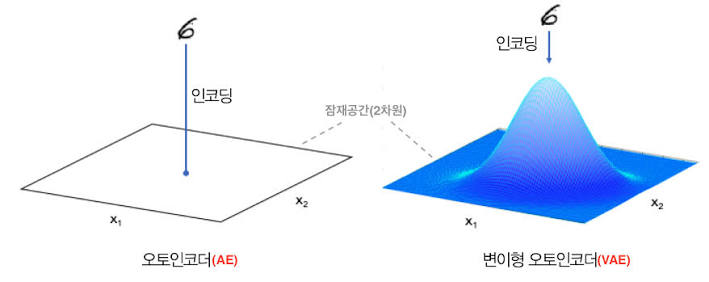

| 구분 | AE | VAE |
| --- | --- | --- |
| **잠재 공간 모양** | 사용자 벡터가 듬성듬성 흩어지고, 벡터 사이의 빈 공간은 학습되지 않음 | KL 항이 분포를 N(0, 1) 쪽으로 당겨, 사용자들이 중심 근처에 모임 |
| **기록이 적은 사용자 (희소한 데이터)** | 몇 개 안 되는 기록만으로 위치가 확정되어, 우연한 기록 (노이즈) 때문에 엉뚱한 곳에 놓이기 쉬움 | 근거가 부족한 만큼 중심 쪽으로 당겨져, 비슷한 사용자들 근처에 안정적으로 놓임 |

**VAE-CF의 주요 장점**

1. **확률적 잠재 분포 모델링 (불확실성 반영)**

- 기존 MF처럼 단일 포인트 벡터가 아닌 확률적 잠재 분포로 사용자 선호를 모델링하여, **예측 시의 불확실성을 반영하고 노이즈의 영향을 줄임**

2. **희소한 상호작용 데이터에서도 안정적**

- KL Divergence를 통해 잠재 공간을 정규화하여, 기록이 적은 사용자도 비슷한 사용자들 근처에 안정적으로 표현되며 **희소성 문제에 효과적으로 대응**

3. **비선형성 학습**

- 신경망 구조를 통해 MF의 한계였던 **복잡하고 비선형적인 패턴을 학습**하여 추천 성능 높임




## **2. GNN 기반 사용자 선호 예측**

### **2-1. GNN (Graphic Neural Network, 그래프 신경망)**

#### **그래프 (Graph)**

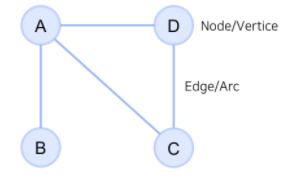

: 노드 (Node)와 그 노드를 잇는 선(Edge)을 모아 구성한 자료 구조

- 노드 (Node / Vertex): 개체 (사용자, 아이템, 사람, 원자 등)
- 엣지 (Edge / Arc): 노드 사이의 관계나 상호작용
    - 방향을 가질 수 있음: ‘A가 B를 팔로우'와 ‘B가 A를 팔로우'는 다름
    - 가중치를 가질 수 있음: 평점 5점, 구매 3회 등

#### **그래프를 사용하는 이유?**

1. **추상적인 개념(관계, 상호작용 등)** 을 다루기에 적합

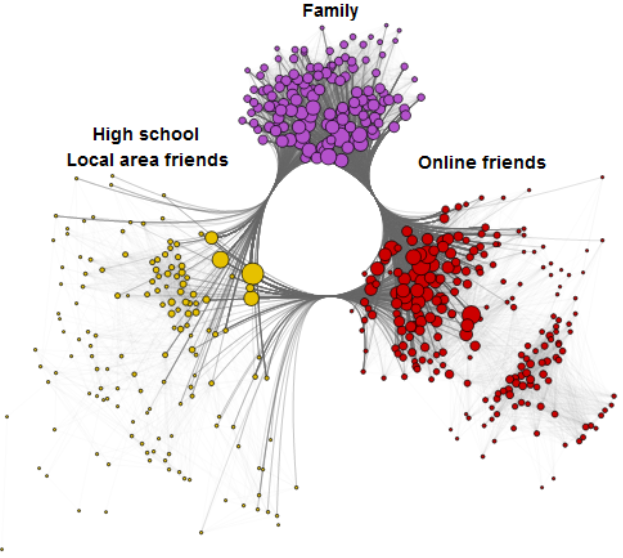

2. **Non-Euclidean space** 표현하고 학습 가능
    - 그래프는 격자 구조가 없는 비유클리드(Non-Euclidean) 공간의 데이터를 노드와 엣지로 표현하는 자료구조. GNN은 이를 직접 입력으로 받아 학습.

    | 데이터 | 구조 | 이웃의 형태 |
    | --- | --- | --- |
    | 이미지 | 픽셀이 바둑판처럼 배열된 격자 | 모든 칸이 상하좌우 이웃을 가지고 순서가 고정됨 |
    | 텍스트 | 단어가 일렬로 놓인 시퀀스 | 앞뒤 이웃이 정해져 있음 |
    | SNS·분자·추천 | 그래프 | 노드마다 이웃 수가 제각각이고 정해진 순서나 좌표가 없음 |

    이미지와 텍스트는 이웃 구조가 고정되어 CNN, RNN을 적용할 수 있지만, 그래프는 노드마다 이웃 구조가 달라 GNN이 필요.

**Non-Euclidean space란?**

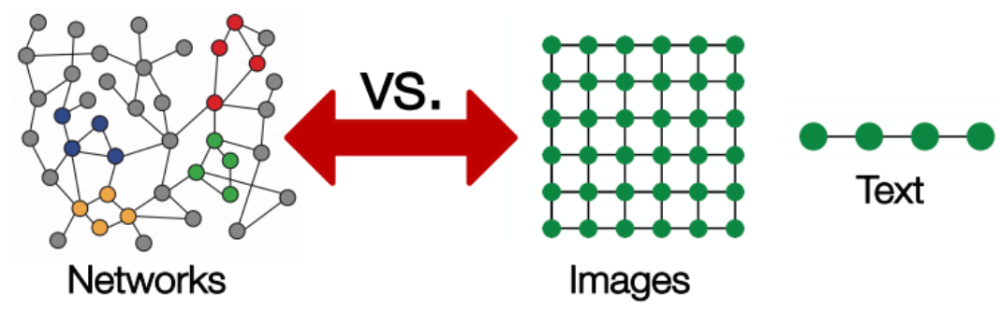
- **Euclidean space**: Rⁿ처럼 좌표와 거리가 정의된 공간입니다. 이미지와 텍스트처럼 규칙적인 격자 위에 놓인 데이터가 여기에 속합니다.
- **Non-Euclidean space**: 고정된 좌표나 격자가 없는 공간입니다. 노드 번호를 바꿔도 같은 그래프입니다.

### **2-2. GNN의 구조**

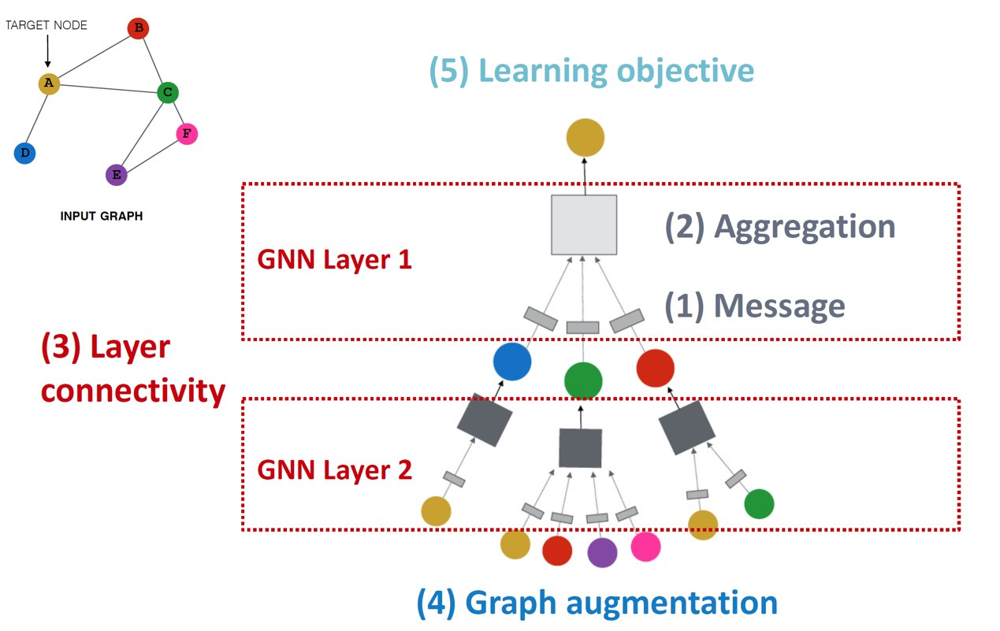

1. **그래프 구조 생성** : 노드와 엣지를 정의하고, 각 노드에 초기 피처(임베딩)를 부여
2. **메시지 패싱** : 각 노드가 이웃 노드로부터 정보를 받아 전달
    1. **메시지 생성** : 각 이웃 노드가 자신의 임베딩으로 전달할 메시지 생성
    2. **집계** : 타깃 노드가 받은 메시지들을 하나로 합침 (평균, 합, 최대값, attention 등)
    3. **갱신** : 집계 결과와 자신의 이전 임베딩을 결합해 새 임베딩을 만듦
3. **최종 출력**

### **2-3. GNN 프로세스**

**이러한 데이터가 있다고 가정** 

| 사용자 | 사용자 특징 | 영화 | 영화 특징 | 평점 |
| --- | --- | --- | --- | --- |
| U1 | 20대 | A | 액션, 평균 평점 4.3점 | 5 |
| U1 | . | B | 스릴러, 평균 평점 4.1점 | 4 |
| U2 | 30대 | A |  | 3 |
| U2 | . | C | SF, 평균 평점 4.8점 | 5 |
| U3 | 20대 | C |  | 4 |

#### **1. 그래프 구조 생성**

: GNN에서의 첫 번째 단계 -> 노드와 엣지 정의, 각 노드에 피처 부여

- 노드: 사용자 3개(U1, U2, U3) + 영화 3개(A, B, C) = 총 6개
- 엣지: 평점 기록 5개
    - 예: U1이 영화 A에 5점을 줬으므로 `U1 –(5점)– A` 엣지 생김
- 영화 A와 C는 각각 하나의 노드이므로, 전체 그래프는 `B — U1 — A — U2 — C — U3`로 연결된 하나의 그래프!

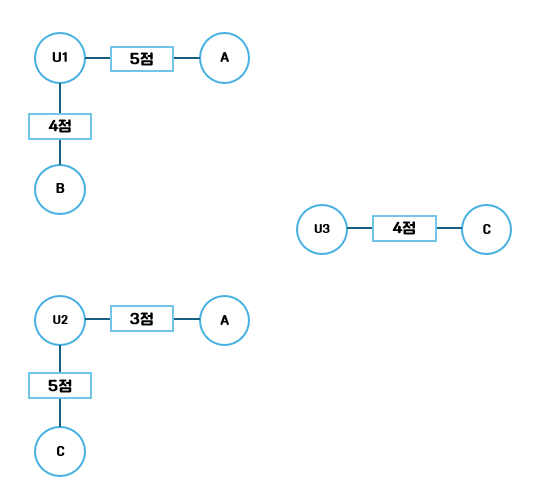

#### **2. 메시지 패싱 (Message Passing)**

GNN 레이어 : ‘메시지 생성 - 집계 - 갱신’ 의 세 단계로 이루어짐. GNN이 K개의 레이어로 구성되어 있다면 이 과정이 K번 반복. 임베딩을 갱신하는 대상 노드를 **타깃 노드**라고 하며, 모든 노드가 한 번씩 타깃 노드가 된다!

**U1을 타깃 노드로 한 경우 메시지 패싱 단계**

| 단계 | 내용 | U1의 경우 |
| --- | --- | --- |
| 메시지 생성 | 이웃 노드가 자신의 임베딩으로 메시지를 생성 | 영화 A, B가 각자의 임베딩을 메시지로 생성 |
| 집계 | 받은 메시지를 하나의 벡터로 합침 | A, B의 메시지를 평균해 하나의 벡터로 요약 |
| 갱신 | 집계 결과와 자신의 이전 임베딩을 결합해 새 임베딩 계산 | U1의 이전 임베딩과 요약 벡터를 결합해 U1의 임베딩 갱신 |

이와 같은 과정이 **U2, U3, A, B, C 모든 노드**에서 동시에 수행!

**1. 메시지 생성** : 각 노드가 이웃에게 보낼 자신의 정보 생성

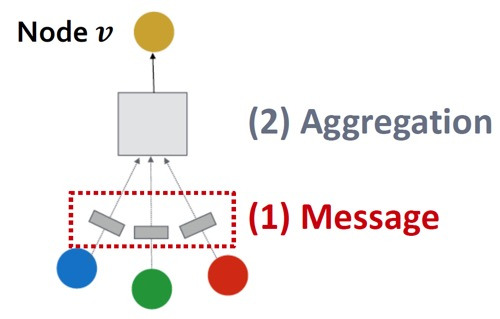

- 이때, 이웃에게 보내는 메시지는 임베딩 되어 있음
- 노드는 연결된 이웃마다 전달할 메시지를 생성하기 위해 메시지 함수를 사용
- 메시지 함수 수식

    $m_u^{(l)} = MSG^{(l)}(h_u^{(l-1)})$

    - $h_u^{(l-1)}$ : 이전 레이어($l-1$번째 레이어)의 결과인 $u$ 노드의 임베딩
    - $m_u^{(l)}$ : 현재 레이어($l$ 번째 레이어)에서 계산된 $u$ 노드의 메시지

**2. 집계 (Aggregation)** : 메시지 생성 이후, 여러 이웃 노드에서 받은 메시지를 하나의 벡터로 통합하는 단계 거침

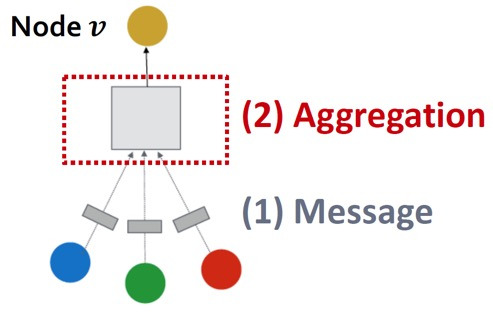

- sum, mean, max, attention-weighted sum 등의 다양한 aggregator를 사용합니다.
- 집계 함수 수식
    
    $h_v^{(l)} = AGG^{(l)} ({m_u^{(l)}|  u \in N(v)})$

**3. 갱신 (Update)** : 집계된 이웃 정보와 자신의 이전 상태를 결합해 새로운 임베딩 계산

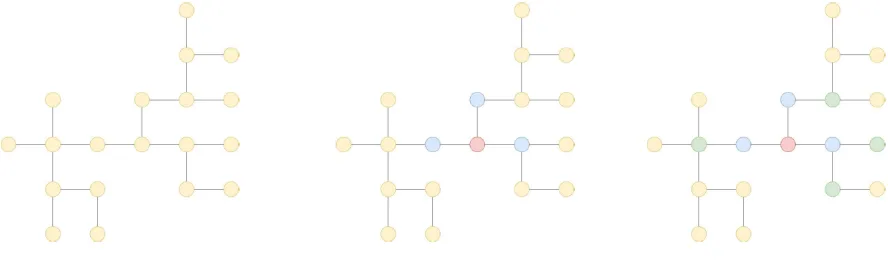

- 그리고 이 과정을 $l$ 번 반복함으로써 더 멀리 있는 이웃의 정보까지 반영!
    - 예를 들어, 이 과정을 1회 수행하면 한 단계 떨어진 이웃의 정보가 반영되고, $l$ 번 반복하면 $l$ 단계 만큼 떨어진 이웃의 정보를 반영할 수 있다!
- 갱신 함수 수식

    $h_v^{(l)} = Combine(AGG^{(l)} ({m_u^{(l)}| u \in N(v)}), m_v^{(l)})$

    - $m_v^{(l)}$ : $v$ 노드의 메시지
    - (이웃 정보를 요약한 $m_u^{(l)}$ 벡터) + (타겟 노드 자신의 정보) ⇒ 하나의 긴 벡터로 결합

    $h_v^{(l+1)} = \sigma (W^{(l)} \cdot h_v^{(l)})$

    - 결합된 벡터가 신경망 레이어($W^{(l)}$)와 활성화 함수($\sigma$)를 통과하며 갱신 완료

### **2-4. LightGCN (Light Graph Convolutional Networks)**

#### **주요 GNN 아키텍처**

**1. GCN (Graph Convolutional Network)** : 그래프 위에서 Convolution 연산 수행. 이웃 노드와 타겟 노드에 동일한 파라미터 적용.
    
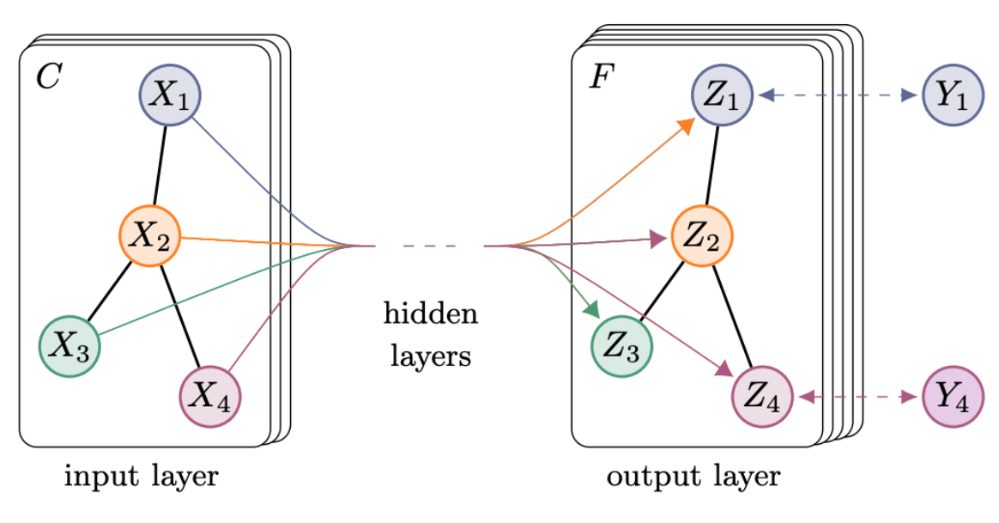

**2. GRN (Graph Recurrent Network)** : RNN + GNN 결합. 시간에 따라 노드 특성이 업데이트 되어 그래프의 동적 변화 포착 가능. 
    
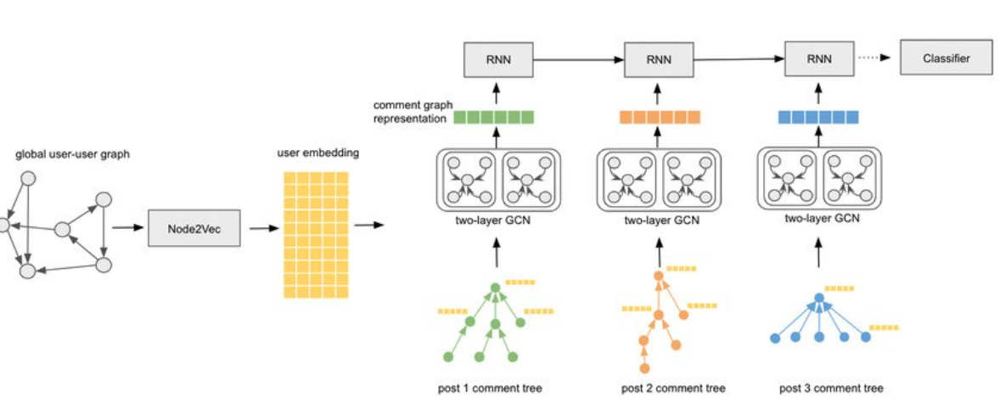
    
**3. GAT (Graph Attention Network)** : 이웃 노드 간 중요도를 학습해 가중 평균. 타겟 노드의 이웃 노드 중 중요한 노드에 가중치를 둠.
    
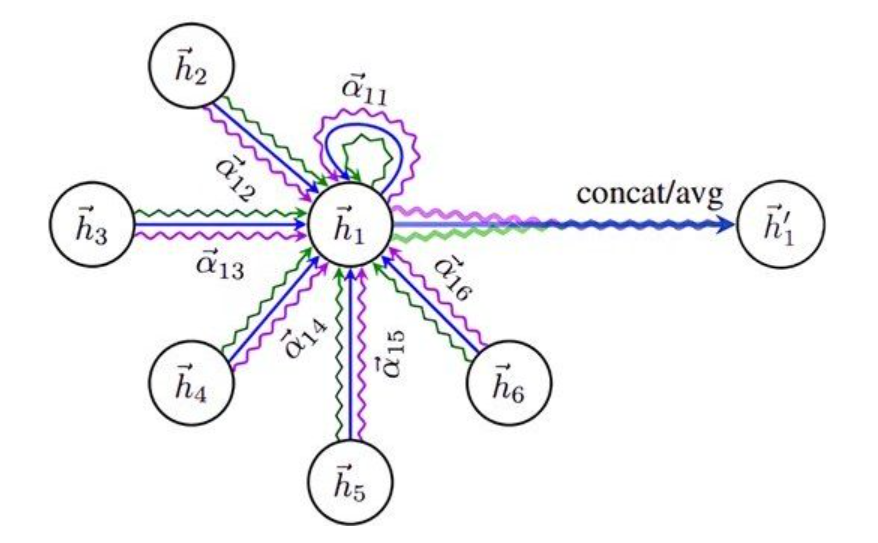
    

**4. GraphSAGE** : 대규모 그래프에 대해 샘플링 기반으로 학습. 이웃 노드와 타겟 노드의 가중치 값을 더하지 않고 concat함.
    
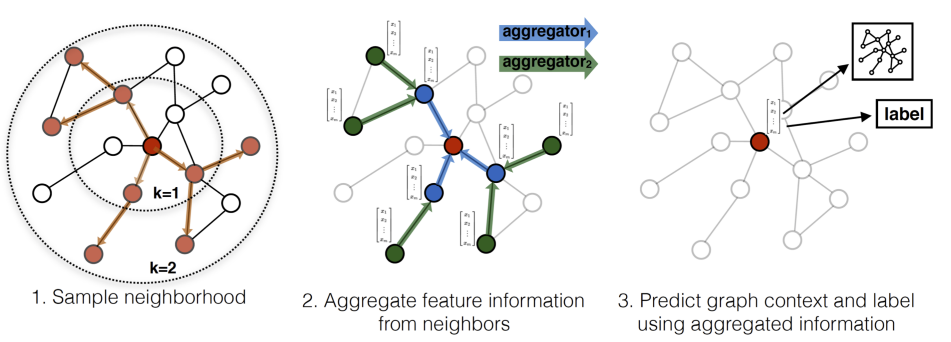

**총정리**

| 아키텍처 | 작동 방식 | 특징 |
| --- | --- | --- |
| **GCN** (Graph Convolutional Network) | 이웃 임베딩을 연결 수(차수)로 정규화해 평균 | 가장 기본적인 구조. 학습 시 전체 그래프가 필요 |
| **GRN** (Graph Recurrent Network) | RNN 구조를 GNN에 결합 | 시간에 따라 변하는 그래프(동적 관계)를 포착 |
| **GAT** (Graph Attention Network) | 이웃마다 attention으로 중요도를 학습해 가중 평균 | 중요한 이웃에 집중하지만 계산량이 늘어남 |
| **GraphSAGE** | 이웃을 일부만 샘플링하고, 이웃 정보를 더하지 않고 자기 정보와 concat | 대규모 그래프와 **학습 때 없던 새 노드**에도 적용 가능 |

#### **LightGCN?**

**탄생 배경**

NGCF는 노드 분류용 GCN의 연산을 그대로 사용해, 레이어마다 가중치 행렬 W를 곱하고 **비선형 활성화 함수**를 적용. 그러나 추천 그래프의 노드에는 사용자 ID와 아이템 ID에 해당하는 **ID 임베딩**만 있어, 두 연산은 오히려 학습을 방해함.

-> 따라서 Light GCN은 두 연산을 제거하고, 추천의 핵심인 사용자-아이템 간 **연결 관계**만 전달하도록 구조를 단순화!!

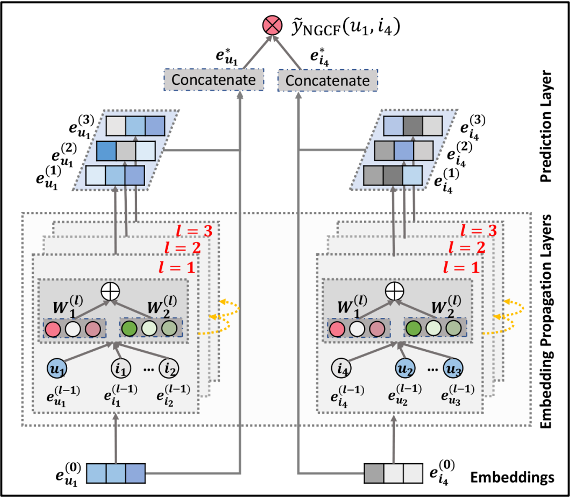

(NGCF의 아키텍처 (GNN))

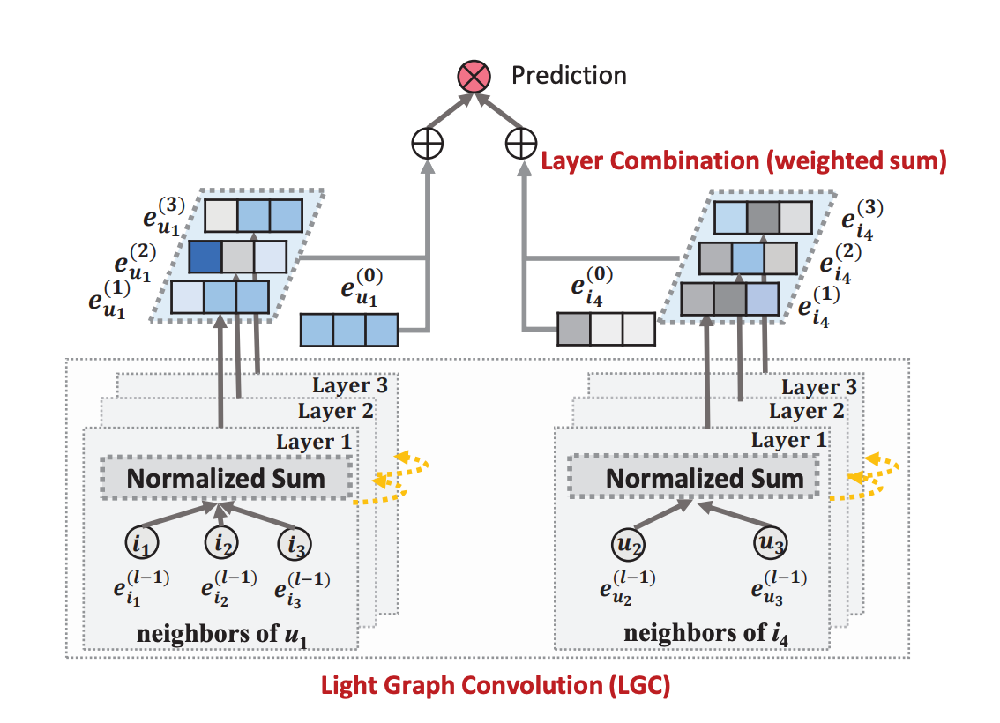

(LightGCN의 아키텍처)

**제거한 GNN 구성 요소 2가지**

1. **특징 변환(Feature Transformation) 제거**
    - 레이어마다 복잡했던 학습 파라미터 ($W^{(l)}$) 삭제
2. **비선형 활성화 함수 (Non-linear Activation) 제거**
    - ReLU와 같은 활성화 함수를 사용하지 않고, 이웃 정보를 합침 
    → 주로 정규화된 합 혹은 평균 사용
    - 왜 활성화 함수를 제거했나요?
        - 임베딩 전파 과정에서 이미 비선형성이 충분히 반영 됨
        - 과적합을 방지


### **2-5. GNN 활용 사례**

#### **Pinterest**

-> 약 30억 개의 노드와 180억 개의 엣지로 구성된 그래프 속에서 사용자들이 상호작용하는 핀, 보드, 카테고리를 분석해 추천

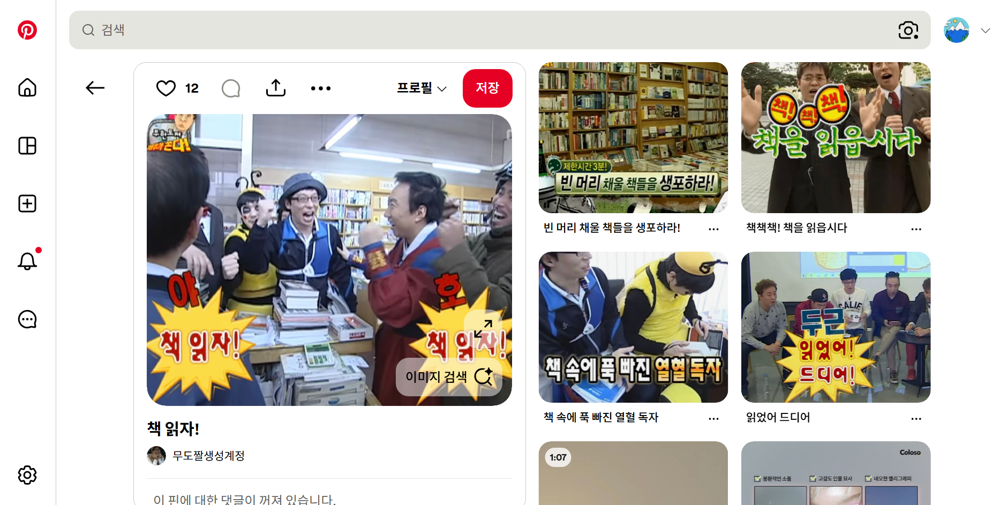

(하나의 이미지를 선택하니 유사한 이미지들을 추가로 보여줌. 이 방법이 GNN!)

- **그래프 구성:** 사용자가 저장한 이미지(핀)와 핀을 모아 둔 보드를 노드로, '핀이 보드에 저장됨'을 엣지로 하는 그래프
- **규모:** 약 30억 개의 노드와 180억 개의 엣지, 75억 개의 학습 예시
- **해결 방식:** 이 규모에서는 전체 그래프 연산이 불가능. 그래서 GraphSAGE처럼 각 노드의 이웃 중 중요한 일부만 샘플링해 학습

#### **그 외 활용분야**
- **소셜 네트워크:** 서로 알고 있는지, 어떤 경로로 알고 있는지 카테고리화, 친구로 추천하려면 엣지로 얼마나 가까워야 하는지 등

- **추천 시스템:** 사용자-아이템 관계 분석
    
    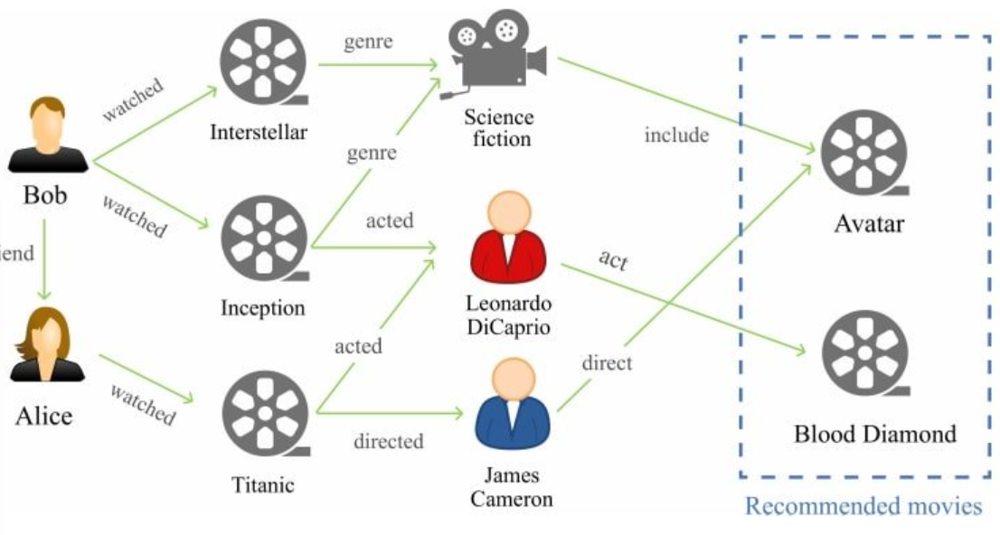
    
- **화학 및 생명과학:** 분자 구조 분석 및 특성 예측, 약물 상호작용 예측 등
    - 노드 = 하나의 분자/원자
    - 엣지 = 분자/원자 간 결합
    - 각 노드와 엣지의 피쳐
    
    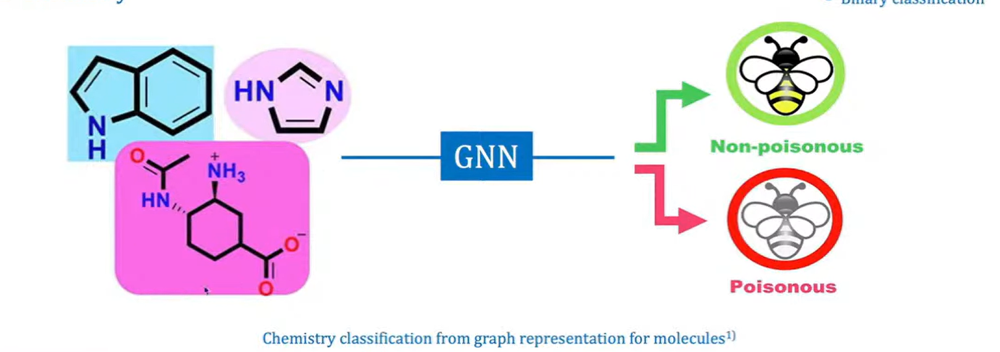
    
- **금융 및 보안:** 이상 거래 탐지, 악성 사용자 분류

- **Traffic :** 한 장소에서 다른 장소까지 시간이 얼마나 걸리는지
    
    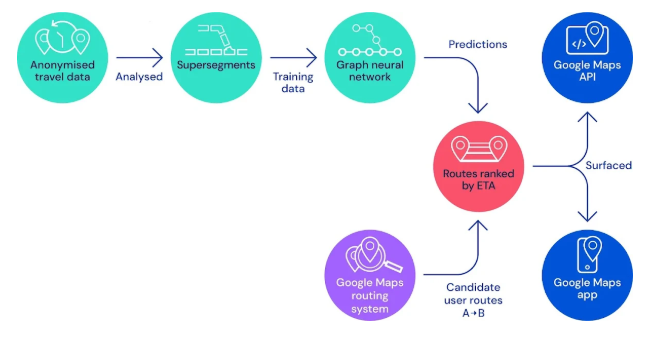
    
- **프로그램 분석 :** 프로그램 내에서 코드에 대해 auto suggestion
    
    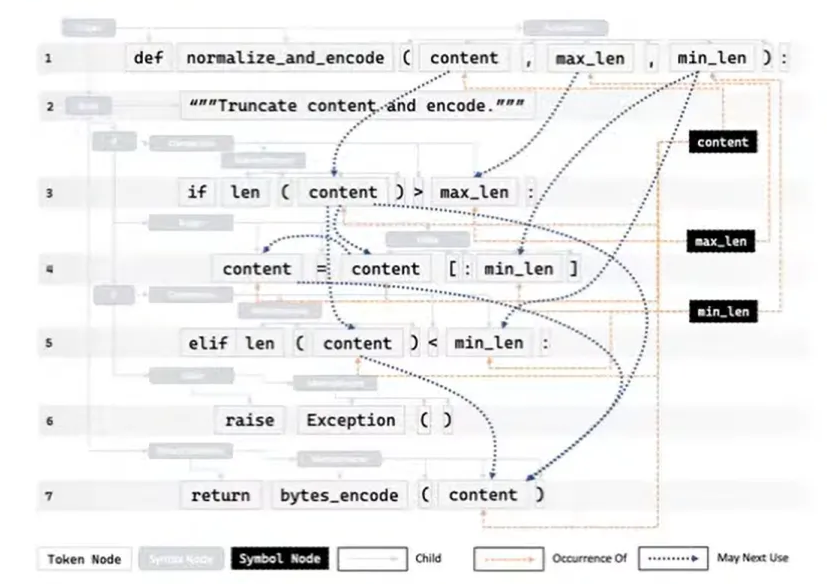

### **2-6. GNN 장단점**

#### **장점**

1. **고차원 협업 시그널 (High-order Collaborative Signals) 포착**
    
    단순히 '나'의 잠재 요인(MF, VAE) 분석을 넘어, 나와 취향이 비슷한 사용자들(이웃)과 내가 본 아이템과 연관된 다른 아이템들의 정보를 직접 반복해서 반영 가능
    
2. **정형화되지 않은 데이터 학습 가능**
    
    GNN은 ‘관계’를 학습하기 때문에, 상호작용, 소셜 관계, 지식 그래프, 사용자 속성을 하나의 그래프에 함께 담아 학습 가능
    
3. **Cold Start 문제 완화에 효과적**
    
    상호작용이 없는 신규 아이템도 속성 노드나 이웃 정보를 통해 임베딩을 얻을 수 있음

#### **단점**

1. **과평탄화 (Over-smoothing) 문제**
    
    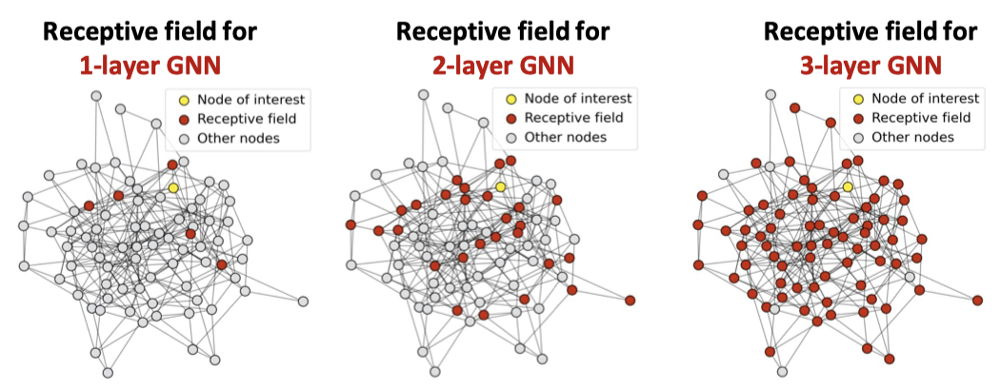
    
    모든 노드의 임베딩이 같은 값으로 수렴하는 현상. 메시지 전달을 많이 반복하여 GNN 모델의 레이어가 많아질수록, 연결된 그래프 내의 모든 노드 간의 임베딩이 비슷해지는 문제가 발생.
    
2. **과압축 (Oversquashing) 문제**
    
    단계마다 기하급수적으로 늘어나는 이웃 정보를 고정 크기 벡터에 담으면서 먼 노드의 정보가 손실됨.
    
3. **계산 복잡도 증가**
    
    실제 세계에서는 수십억 개의 노드와 엣지가 포함된 그래프에 GNN을 적용해야 하므로 막대한 자원과 메모리가 요구됨.
    
4. **순서 반영의 어려움**
    
    GNN은 모든 상호작용을 집합으로 보지만, 순서를 반영하지는 못함. ‘신발 → 바지 → 셔츠’ 순서로 구매한 것과 ‘셔츠 → 바지 → 신발’ 순서로 구매한 것이 같은 그래프가 되므로, 다음 행동을 예측하기 어려움.


## **3. Transformer 기반 추천 시스템**

### **3-1. 기존 추천 시스템의 순차적 한계**

**CF의 순차적 한계**
- **순서 무시**: 같은 아이템을 샀다면 구매 순서가 달라도 같은 사용자로 인식.
- **문맥 부족**: '방금' 한 구매와 ‘1년 전' 구매의 중요도 구분 불가.
- **예측의 한계**: '다음' 행동보다는 '일반적인' 선호를 예측하는 데 초점을 맞춤.

**GNN의 순차적 한계**
- **지역적 정보 전파의 한계**
    - `[A → B → C]`에서 C가 A의 정보를 받으려면 반드시 B를 거쳐야 함. (레이어 2개 필요)
    - 거치는 동안 정보가 희석되고 압축됨. (과압축 문제)
- **장기 의존성 문제**
    - GNN은 레이어 수만큼의 단계까지만 볼 수 있어, 멀리 떨어진 행동 간의 관계를 포착하기 어려움.
    - 반면 Self-Attention은 시퀀스 안의 모든 아이템 쌍을 거리와 상관없이 한 번에 직접 비교!

### **3-2. Transformer : 사용자 행동을 순서(sequence)로 접근**

#### **예시 1. '문맥'에 따라 달라지는 동일 아이템의 의미 (Self-Attention)**

: 같은 아이템이라도 함께 등장한 아이템에 따라 다르게 해석됨.

|  | 문맥 ① | 문맥 ② |
| --- | --- | --- |
| 행동 순서 (클릭 시퀀스) | 수영복 → 비치타월 → **선크림** | 스킨 → 로션 → **선크림** |
| Transformer의 해석 | 선크림이 수영복, 비치타월과 강하게 Attention됨 | 선크림이 스킨, 로션과 강하게 Attention됨 |
| 해석된 선크림의 의미 | 휴가 준비물 | 데일리 스킨케어 단계 |
| 다음 추천 결과 | 방수팩, 래시가드 | 클렌징폼, 선크림 리필 |

#### **예시 2. 시간 순서를 뛰어넘는 '핵심 의도'의 포착 (Long-Range Dependency)**

: 다음 행동과 관련된 아이템이 가장 최근이 아닌 시퀀스 앞부분에 있는 경우. Transformer는 현재 시점과 과거 모든 아이템의 관련성을 한번에 계산하므로, 거리와 관계없이 프린터에 높은 가중치 줄 수 있음. 그 결과 토너처럼 프린터 관련 상품 추천함!

✅ 순차적으로 정보를 전달하는 RNN이나 GNN에서는 5단계를 거치며 프린터의 정보가 희석되지만, Transformer는 이를 직접 반영!!

### **3-3. Transformer의 핵심 : Self-Attention**

: Self-Attention은 시퀀스 안의 모든 아이템 쌍의 관련성을 거리와 상관없이 동시에 계산함. 그래서 프린터와 토너 예시처럼 두 아이템 사이에 많은 행동이 끼어 있어도 둘을 직접 연결할 수 있고, 이를 통해 장기 의존성 문제를 해결가능!

#### **동작 원리 : Query, Key, Value**

| 개념 | 정의 | 역할 | 예시 (선크림 예시) |
| --- | --- | --- | --- |
| Query (Q) | 아이템 임베딩 × 가중치 행렬 W_Q | 현재 아이템이 다른 아이템과의 관련성을 계산하는 기준 | 선크림의 Query 벡터 |
| Key (K) | 아이템 임베딩 × W_K | Query와 내적되어 관련성 점수를 결정 | 수영복, 비치타월, 양말의 Key 벡터 |
| Value (V) | 아이템 임베딩 × W_V | 관련성 점수에 따라 가중합되는 실제 정보 | 수영복, 비치타월, 양말의 Value 벡터 |

#### **연산 과정 : "관련성"을 계산하여 "가중치"를 만들다**

Self-Attention의 연산은 `Attention(Q, K, V) = softmax( Q·Kᵀ / √d ) · V`로 표현. 먼저 현재 아이템의 Query와 각 아이템의 Key를 내적해 관련성 점수를 구함. 그 다음 Softmax로 이 점수를 합이 1인 가중치로 바꾸고, 각 아이템의 Value에 그 가중치를 곱해 더함.

**예시 : 수영복, 비치타월, 양말이 함께 있는 시퀀스 가정. 선크림 기준 진행**

1. **Attention Score 계산 (Q · K)**
    - 선크림의 Query와 각 아이템의 Key를 내적해 관련성 점수를 계산
    - 예: 수영복 2.0 / 비치타월 1.5 / 양말 0.1
2. **가중치 변환 (Softmax)**
    - 점수를 합이 1이 되는 비율로 바꿈.
    - 결과: 수영복 57.0% / 비치타월 34.5% / 양말 8.5%
3. **가중합 (Score · V)**
    - 각 아이템의 Value에 비율을 곱해 더함.
    - 선크림의 출력 = 0.570 × V(수영복) + 0.345 × V(비치타월) + 0.085 × V(양말)

-> 선크림 출력 벡터는 수영복, 비치타월의 정보가 약 92%를 차지하므로 '휴가 준비물'로 해석. 이처럼 **관련성에 따라 정보 반영 비율을 다르게 적용하는 것**이 Self-Attention의 핵심!!

### **3-4. Transformer 기반 주요 추천 시스템 모델**

#### **SASRec**

: 단방향 어텐션으로 과거 정보만 활용해, 다음 아이템을 예측하도록 학습한 모델

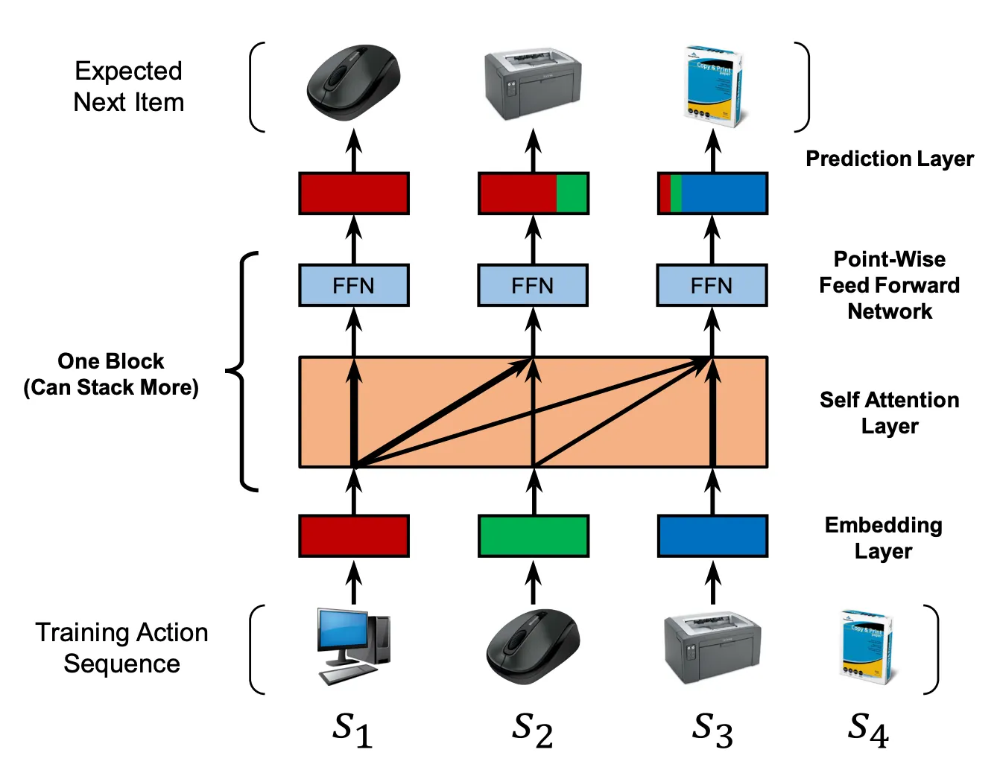

- **입력**: 시간순 행동 시퀀스 (컴퓨터 → 마우스 → 프린터 → 소프트웨어). 각 위치의 정답은 바로 다음 아이템
- **Embedding Layer**: 아이템 임베딩에 위치 임베딩을 더함
- **Self Attention Layer**: 과거 아이템만 참조. 그래서 화살표가 왼쪽에서 오른쪽(과거 → 현재)으로만 그려져 있음.
- **FFN**: 위치별로 비선형 변환을 적용.
- **Prediction Layer**: 출력 벡터와 아이템 임베딩을 내적해 다음 아이템의 점수를 계산.

**정리**

- **방식**: 단방향 어텐션 (GPT와 유사)
- **어텐션 계산**: 과거 아이템만 참조할 수 있음.
- **목표**: 다음 아이템 예측 (Next-item prediction)
    - 예: [노트북 → 마우스 → 키보드] → 다음은 '노트북 거치대'
- **특징**
    1. 적응적 집중: 데이터가 희소하면 최근 아이템에, 풍부하면 긴 과거 맥락에 집중하도록 Attention을 조절.
    2. 빠른 학습: RNN처럼 순서대로 계산하지 않고 모든 위치를 병렬로 처리.
- **문제점**
    1. 계산량: Attention 연산량이 시퀀스 길이의 제곱(n²)에 비례해, 긴 행동 이력을 다루기 부담스러움.
    2. 단방향성: 과거 방향만 참조하므로 시퀀스 앞부분의 아이템은 활용할 정보가 적음. 또한 장바구니에 동시에 담은 물건처럼, 실제 행동 순서가 엄격하지 않은 경우도 존재.

#### **BERT4Rec**

: 양방향 어텐션으로 과거와 미래 정보를 모두 활용해, 가려진 아이템을 예측하도록 학습한 모델

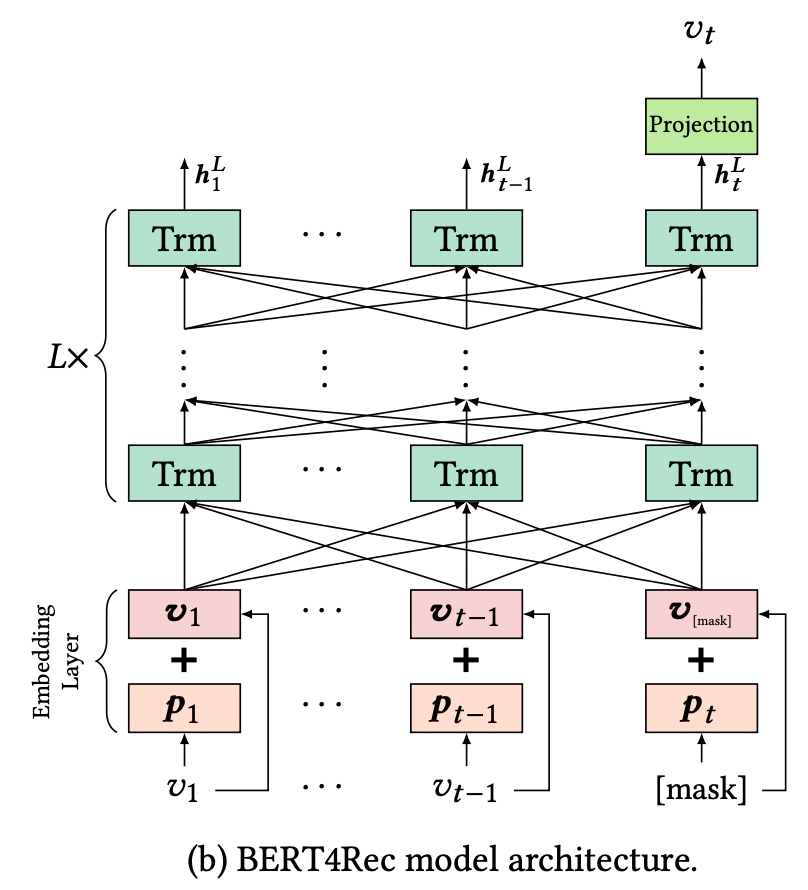

- **입력**: 시퀀스의 일부 아이템을 `[mask]`로 가림.
- **Embedding Layer**: 아이템 임베딩(v)에 위치 임베딩(p)을 더함.
- **Trm × L**: 양방향 Self-Attention을 L층 쌓은 구조. 화살표가 교차하는 것은 앞뒤 위치를 모두 참조한다는 뜻.
- **Projection**: `[mask]` 위치의 출력으로 원래 아이템을 예측.

**정리**

- **방식:** 양방향 어텐션 (BERT와 유사)
- **어텐션 계산:** 시퀀스의 일부를 `[MASK]` 토큰으로 가리고, 가려진 위치가 과거와 미래의 모든 아이템을 참조할 수 있음.
    - `[MASK]` 로 가리는 이유?
        - 모델이 양방향으로 학습하면서 target 아이템의 정보를 직접 보게 되는 정보 누출(information leakage)이 발생할 수 있기 때문!
- **목표:** 가려진 아이템 예측 (Masked-item prediction)
    - 예: [노트북 → 마우스 → `[MASK]` → 키보드] → 앞뒤 문맥으로 `[MASK]` = '노트북 거치대'를 예측
- **특징:**
    1. 양방향 문맥: 각 아이템의 앞뒤 문맥을 모두 학습에 사용.
    2. 데이터 활용: 한 시퀀스에서 가리는 위치를 바꿔 가며 여러 학습 샘플을 만들 수 있음.

**SASRec vs. BERT4R3ec**

| 구분 | SASRec | BERT4Rec |
| --- | --- | --- |
| 어텐션 방향 | 단방향 (과거만) | 양방향 (과거 + 미래) |
| 학습 목표 | 다음 아이템 예측 | 가려진 아이템 예측 |
| 학습 효율 | 빠름 | 상대적으로 느림 |

**상황별 선택 기준**

| 상황 | 유리한 모델 | 이유 |
| --- | --- | --- |
| 상호작용이 많고, '다음 행동' 예측이 목적 (실시간 피드, 커머스) | SASRec | 학습·추론 효율이 높고, 손실 함수를 맞추면 성능도 동등 이상 |
| 상호작용이 적어 시퀀스가 짧은 경우 | 상황에 따라 다름 | BERT4Rec은 한 시퀀스에서 여러 마스킹 샘플을 만들 수 있어 데이터 증강 효과가 있지만, 손실 함수를 맞추면 차이가 줄어든다는 반론도 있음 |
| 행동 순서가 느슨한 도메인 (장바구니에 동시에 담기 등) | BERT4Rec | 양방향 문맥이 의미 있음 |


## **4. 제언 : 오늘날의 추천 시스템**

### **4-1. LLM의 시대**

#### **관점의 전환 : 추천을 랭킹 문제가 아닌 언어 문제로 푼다!!**

- 과거 : 조합별로 미리 학습된 공식에 따른 **점수** 출력

- LLM : 추천을 점수 계산이 아닌 **문장**으로 출력
    - ID가 아닌 의미(Semantic) 기반 추천
    - 텍스트, 이미지, 오디오 등 멀티모달 데이터 활용

    - 점수 대신 추천 이유를 함께 제시하는 **서술형 추천**이 가능해짐!

#### **새로운 가능성**

1. **대화형 추천** : 사용자가 자연어로 입력한 조건을 반영해 추천.
    - *예시: "비 오는 일요일에 혼자 보기 좋은, 너무 슬프지 않은 영화 추천해줘"*
2. **Zero-shot 추천** : 상호작용 데이터 없이 텍스트 설명만으로 추천.
    - *신상품이 등록된 첫날, 구매 기록이 0건이어도 상품 설명만으로 추천 대상이 될 수 있습니다.*
        
        -  **Cold-Start 문제의 강력한 해결책!**
        
            Cold-Start : 신규 사용자나 아이템의 상호작용 정보가 부족해, 제대로 된 추천이나 예측을 하지 못하는 상황

#### **P5 / TALLRec**

**P5 (Geng et al., RecSys 2022)**

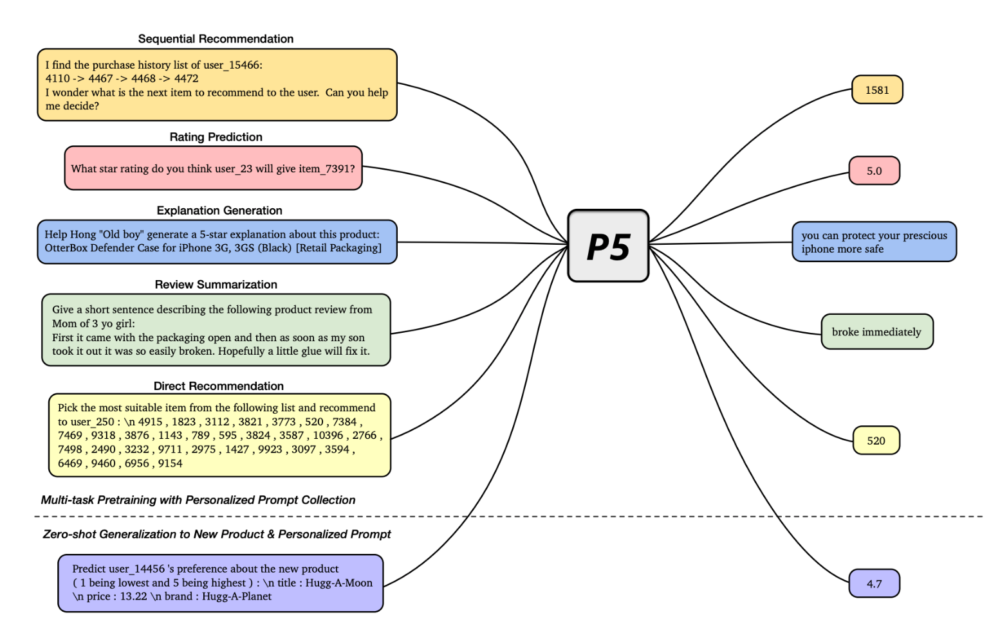

- 여러 추천 과제를 "텍스트 프롬프트 → 텍스트 답변" 형식으로 통일해, 하나의 언어 모델로 학습한 모델.
- 단점 : 언어 모델을 추천 데이터로 처음부터 학습하므로 많은 컴퓨팅 자원과 시간이 필요.

**TALLRec (Bao et al., RecSys 2023)**

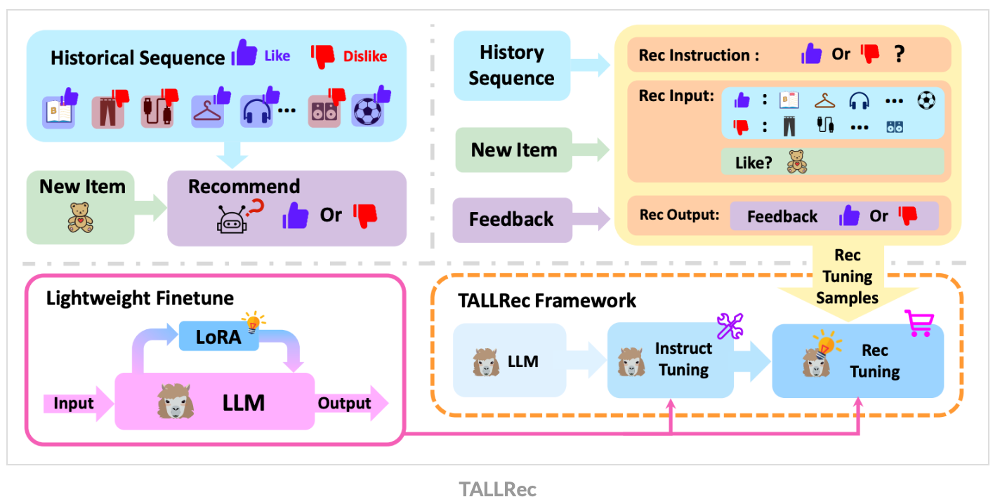

- 학습 비용을 줄이기 위해, 범용 LLM을 "좋아할까? (Yes/No)" 형식의 추천 지시문으로 튜닝하는 프레임워크.
- LoRA로 일부 파라미터만 학습하며, 적은 샘플로도 기존 모델보다 높은 성능을 보고.

### **4-2. 인기 편향과 XAI 문제**

#### **1. 인기 편향 (Polularity Bias)**

: 소수의 인기 아이템이 추천을 독점하고, 대다수의 비인기 아이템은 거의 추천되지 않는 현상.

1. **데이터 불균형**: 상호작용이 인기 아이템에 몰려 있음.
2. **모델의 편향 강화**: 데이터가 많은 아이템일수록 예측 점수가 높아 더 자주 추천.
3. **Rich-get-richer**: 추천 → 노출 → 클릭 → 학습 데이터 반영이 반복되며 격차가 커짐.
        
**사례**
- **Netflix Prize 데이터**: 인기 영화는 전체의 16.5%(2,938편)지만 전체 평점의 약 86%를 차지. **학습 데이터부터 소수에 쏠려 있다는 뜻**
- **Spotify 팟캐스트 추천 실험**: 개인화 추천을 적용하자 스트리밍은 28.90% 증가했지만, 개인의 소비 다양성은 11.51% 감소

-> 비인기·신규 아이템은 노출 기회를 얻기 어렵고, 사용자는 비슷한 콘텐츠만 반복해서 추천받게 되는 문제 발생!

#### **2. 설명가능성 (XAI)**

- 이걸 왜 추천했는지 설명할 수 있는가?
- **문제:** GNN, Transformer 같은 딥러닝 모델은 강력하지만 블랙박스 문제 존재.
- **필요성:** "왜 이걸 나에게 추천했는지" 고객을 설득해야 하고, 비즈니스 담당자에게 추천의 근거를 제시해야 함.

### **4-3. 컴퓨팅 자본, Cold-Start를 고려한 추천시스템 도입**

#### **비용 문제 : 딥러닝은 전면 도입하기엔 너무 비쌈**

1. **GPU 비용**: 대형 모델의 학습·추론에 고가의 GPU가 필요.
2. **실시간 스코어링 서버비**: 요청마다 전체 아이템에 딥러닝 연산을 하면 서버 비용이 급증.
3. **지속 비용**: 대규모 트래픽에서는 사용자 수 × 요청 수만큼의 비용이 매일 누적.

**현업에서는 선형 모델로 후보를 먼저 거르고 딥러닝으로 정렬하는 2단계 구조 사용!**

**1단계 : 후보군 생성**
- **목표** : 수백만 개 아이템 → 수백 개 후보로 축소
- **사용 모델** : 선형 모델 (내용 기반 필터링, 협업 필터링, 행렬 분해)
    - 압도적인 속도 : 딥러닝 모델과 달리 선형 모델은 계산이 단순하여 빠르게 처리 할 수 있음.
    - 비용 효율성 : 학습에 필요한 비용이 훨씬 적음.

**2단계 : 순위 매기기**
- **목표** : 수백 개 후보를 정교하게 정렬해 상위 수십 개를 노출
- **사용 모델** : 딥러닝 모델 (GNN, Transformer, VAE)
    - 높은 정확도 : 추려진 아이템들을 대상으로 복잡한 딥러닝 모델을 사용해 비선형성, 순서, 관계 등 모든 문맥 정보를 총동원하여 최고의 정확도를 뽑아냄
    - 복잡한 패턴 학습 : 사용자 맥락, 아이템 속성, 상호작용 이력을 결합해 선형 모델이 놓치는 패턴을 포착.
